# House segments · Part 1: Data Preparation

The dataset contains 1,359 property records with 27 attributes including the partially-labelled target `Market_segment`.

---
## Step 1 — Environment Setup

In [1]:

# ── Core libraries ────────────────────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

# ── Global plot style ─────────────────────────────────────────────────────────
sns.set_theme(style='whitegrid', palette='muted', font_scale=0.9)
plt.rcParams.update({
    'figure.dpi'        : 130,
    'axes.spines.top'   : False,
    'axes.spines.right' : False,
    'axes.titlepad'     : 6,
    'axes.labelpad'     : 4,
})

# ── Ordered quality scale (used across several plots) ─────────────────────────
QUALITY_ORDER = ['Po', 'Fa', 'TA', 'Gd', 'Ex']   # Poor → Excellent
SEG_ORDER     = ['Budget', 'Affordable', 'Average', 'Premium', 'Exclusive']
SEG_PALETTE   = dict(zip(SEG_ORDER, sns.color_palette('Set2', 5)))

# ── Output directories ────────────────────────────────────────────────────────
# All figures are saved under figures/, all intermediate datasets under datasets/.
# The final rules-compliant dataset goes at the root so the labelling notebook can load it.
from pathlib import Path
FIGURES_DIR = Path('figures')
DATASETS_DIR = Path('datasets')
FIGURES_DIR.mkdir(exist_ok=True)
DATASETS_DIR.mkdir(exist_ok=True)


In [2]:
# ── Load dataset ──────────────────────────────────────────────────────────────
# Place homes_dataset.csv in the same directory as this notebook.
df_raw = pd.read_csv('homes_dataset.csv')

print(f'Dataset loaded: {df_raw.shape[0]} rows × {df_raw.shape[1]} columns')
df_raw.head()

Dataset loaded: 1359 rows × 27 columns


,Id,MSZoning,LotFrontage,LotArea,Neighborhood,YearBuilt,YearRemodAdd,MasVnrArea,ExterQual,Heating,...,BedroomAbvGr,KitchenAbvGr,KitchenQual,Fireplaces,GarageType,GarageCars,PoolArea,PoolQC,MiscFeature,Market_segment
0,1,RL,65.0,8450.0,CollgCr,2003,2003,196.0,Gd,GasA,...,3,1,Gd,0.0,Attchd,2.0,0,NaN,NaN,Average
1,2,RL,80.0,9600.0,Veenker,1976,1976,0.0,TA,GasA,...,3,1,TA,1.0,Attchd,NaN,0,NaN,NaN,Average
2,3,RL,68.0,11250.0,CollgCr,2001,2002,162.0,Gd,GasA,...,3,1,Gd,1.0,Attchd,2.0,0,NaN,NaN,Average
3,4,RL,60.0,9550.0,Crawfor,1915,1970,0.0,TA,GasA,...,3,1,Gd,1.0,Detchd,NaN,0,NaN,NaN,Affordable
4,5,RL,84.0,14260.0,NoRidge,2000,2000,350.0,Gd,GasA,...,4,1,Gd,1.0,Attchd,NaN,0,NaN,NaN,Average


---
## Step 2 — Exploratory Data Analysis (EDA)

The EDA is structured in three blocks:
1. **Statistical audit** — range, mean, variance; identification of anomalies and outliers.
2. **Correlation analysis** — redundant or unexpectedly related features.
3. **Visual inspection** — histograms, count plots, and density plots.

### 2.1 Statistical Audit

In [3]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1359 entries, 0 to 1358
Data columns (total 27 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Id              1359 non-null   int64  
 1   MSZoning        1359 non-null   object 
 2   LotFrontage     1117 non-null   float64
 3   LotArea         951 non-null    float64
 4   Neighborhood    1359 non-null   object 
 5   YearBuilt       1359 non-null   int64  
 6   YearRemodAdd    1359 non-null   int64  
 7   MasVnrArea      1351 non-null   float64
 8   ExterQual       1359 non-null   object 
 9   Heating         1359 non-null   object 
 10  BsmtQual        1323 non-null   object 
 11  TotalBsmtSF     1359 non-null   int64  
 12  1stFlrSF        1359 non-null   int64  
 13  2ndFlrSF        1359 non-null   int64  
 14  GrLivArea       1359 non-null   int64  
 15  FullBath        1359 non-null   int64  
 16  HalfBath        1087 non-null   float64
 17  BedroomAbvGr    1359 non-null   i

In [4]:
# ── Column types and null counts ──────────────────────────────────────────────
# Understanding which columns are numerical vs categorical and how many values
# are missing is the foundation of any data preparation workflow.

null_summary = pd.DataFrame({
    'dtype'        : df_raw.dtypes,
    'null_count'   : df_raw.isnull().sum(),
    'null_%'       : (df_raw.isnull().sum() / len(df_raw) * 100).round(2)
})

print('=== Null value summary ===')
print(null_summary[null_summary['null_count'] > 0].sort_values('null_%', ascending=False).to_string())

# Key observations:
# - PoolQC (99.6%) and MiscFeature (96.2%) are almost entirely null → likely
#   structural (most houses have no pool / no misc feature), not random missingness.
# - LotArea (30%), GarageCars (30%), HalfBath (20%), Fireplaces (20%) have
#   substantial missingness that will require imputation or removal.
# - Market_segment is missing for 100 rows — these are the unlabelled samples.

=== Null value summary ===
                  dtype  null_count  null_%
PoolQC           object        1354   99.63
MiscFeature      object        1307   96.17
LotArea         float64         408   30.02
GarageCars      float64         408   30.02
HalfBath        float64         272   20.01
Fireplaces      float64         272   20.01
LotFrontage     float64         242   17.81
Market_segment   object         100    7.36
GarageType       object          77    5.67
BsmtQual         object          36    2.65
MasVnrArea      float64           8    0.59


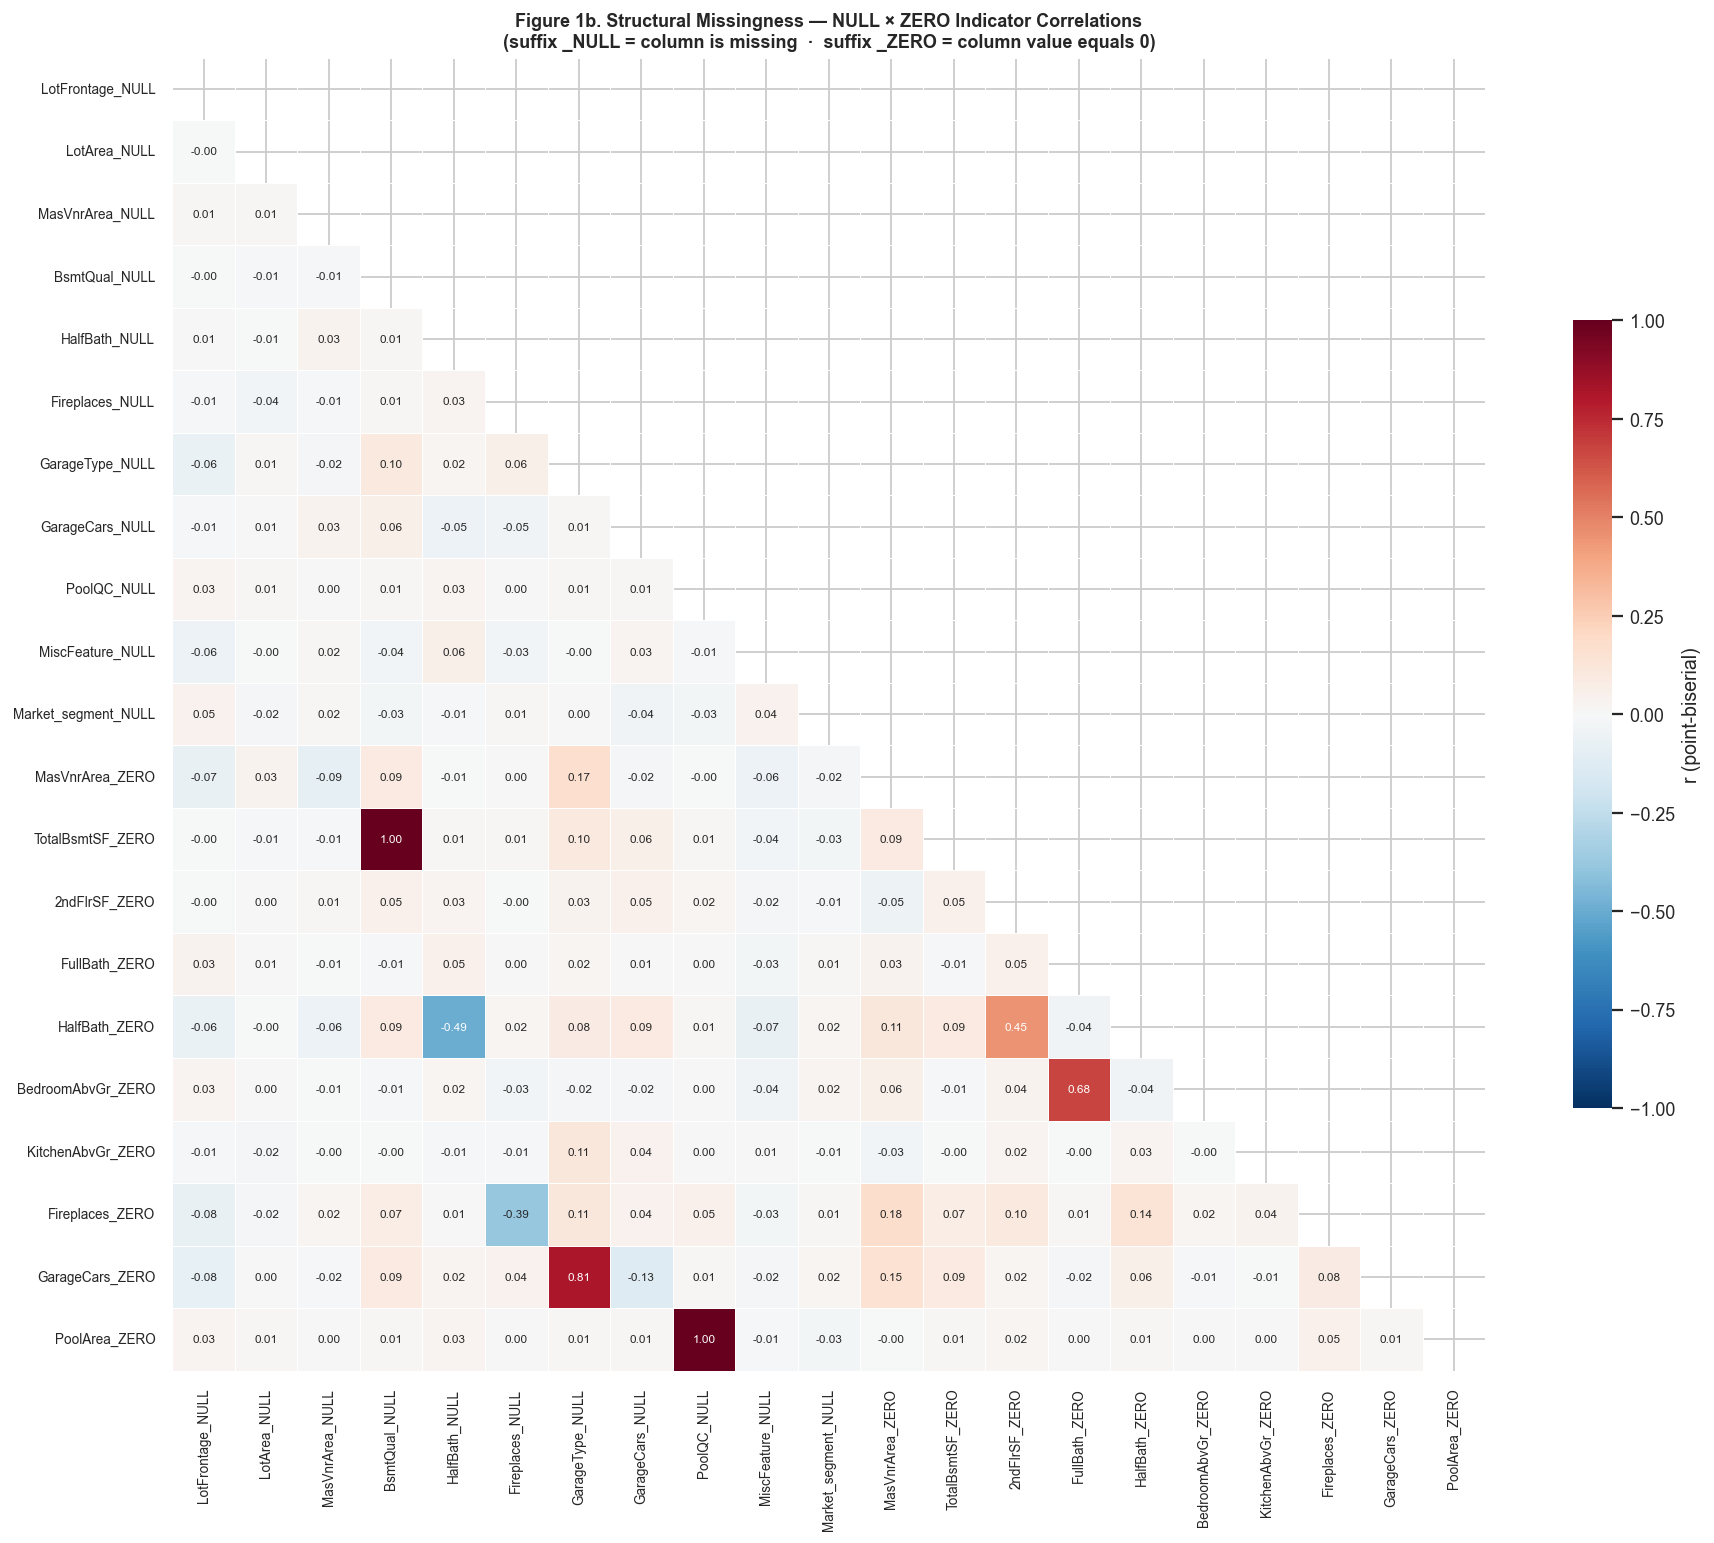

=== Structural missingness candidates  (|r| > 0.30) ===
      Indicator A     Indicator B      |r|
 TotalBsmtSF_ZERO   BsmtQual_NULL 1.000000
    PoolArea_ZERO     PoolQC_NULL 1.000000
  GarageCars_ZERO GarageType_NULL 0.813884
BedroomAbvGr_ZERO   FullBath_ZERO 0.678753
    HalfBath_ZERO   HalfBath_NULL 0.494011
    HalfBath_ZERO   2ndFlrSF_ZERO 0.448595
  Fireplaces_ZERO Fireplaces_NULL 0.385881

Interpretation:
  _NULL ↔ _NULL  →  both columns tend to be missing together (shared missingness mechanism)
  _NULL ↔ _ZERO  →  null in one column coincides with zero in another
                     e.g. PoolQC_NULL ↔ PoolArea_ZERO: no pool → quality field left empty (MNAR)
  Low |r| for all pairs → missingness is random (MAR/MCAR), safe to impute independently


In [5]:
# ── Structural missingness analysis ───────────────────────────────────────────
# Goal: detect MNAR (Missing Not At Random) — nulls that systematically
# co-occur with specific values in other columns.
#
# Strategy:
#  1. Build a binary NULL-indicator per column that has any missing values.
#  2. Build a binary ZERO-indicator for numerical columns that contain zeros.
#  3. Correlate all indicators (point-biserial r) → high |r| signals a
#     structural link, not random missingness.
#  4. Visualise as heatmap; list pairs with |r| > 0.30.

null_cols_any = df_raw.columns[df_raw.isnull().any()].tolist()

null_ind = df_raw[null_cols_any].isnull().astype(int)
null_ind.columns = [f'{c}_NULL' for c in null_cols_any]

zero_cols_any = [c for c in df_raw.select_dtypes(include='number').columns
                 if c != 'Id' and (df_raw[c] == 0).any()]
zero_ind = (df_raw[zero_cols_any] == 0).astype(int)
zero_ind.columns = [f'{c}_ZERO' for c in zero_cols_any]

ind_frame = pd.concat([null_ind, zero_ind], axis=1)
# Drop zero-variance columns (all identical → uninformative)
ind_frame = ind_frame.loc[:, ind_frame.std() > 0]

corr_ind = ind_frame.corr()

# ── Heatmap ───────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(15, 12))
mask_tri = np.triu(np.ones_like(corr_ind, dtype=bool))
sns.heatmap(
    corr_ind, mask=mask_tri,
    annot=True, fmt='.2f',
    cmap='RdBu_r', center=0, vmin=-1, vmax=1,
    linewidths=0.3, linecolor='white',
    square=True, ax=ax,
    annot_kws={'size': 6.5},
    cbar_kws={'shrink': 0.60, 'label': 'r (point-biserial)'}
)
ax.set_title(
    'Figure 1b. Structural Missingness — NULL × ZERO Indicator Correlations\n'
    '(suffix _NULL = column is missing  ·  suffix _ZERO = column value equals 0)',
    fontsize=10, fontweight='bold'
)
ax.tick_params(axis='both', labelsize=7.5)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig1b_missingness_structure.png', bbox_inches='tight')
plt.show()

# ── High-correlation pairs → structural candidates ────────────────────────────
tril_mask = np.tril(np.ones(corr_ind.shape), k=-1).astype(bool)
high_pairs = (
    corr_ind.abs()
    .where(tril_mask)
    .stack()
    .reset_index()
)
high_pairs.columns = ['Indicator A', 'Indicator B', '|r|']
high_pairs = high_pairs[high_pairs['|r|'] > 0.30].sort_values('|r|', ascending=False)

print('=== Structural missingness candidates  (|r| > 0.30) ===')
if high_pairs.empty:
    print('No strong co-missingness patterns detected at |r| > 0.30.')
else:
    print(high_pairs.to_string(index=False))

print()
print('Interpretation:')
print('  _NULL ↔ _NULL  →  both columns tend to be missing together (shared missingness mechanism)')
print('  _NULL ↔ _ZERO  →  null in one column coincides with zero in another')
print('                     e.g. PoolQC_NULL ↔ PoolArea_ZERO: no pool → quality field left empty (MNAR)')
print('  Low |r| for all pairs → missingness is random (MAR/MCAR), safe to impute independently')


In [6]:
# ── Descriptive statistics for numerical features ─────────────────────────────
# We compute range, mean, std (variance proxy), and IQR for every numerical
# column to detect distributional anomalies before any transformation.

num_cols = df_raw.select_dtypes(include='number').columns.tolist()
num_cols.remove('Id')   # Id is an identifier, not a feature

desc = df_raw[num_cols].describe().T
desc['range']    = desc['max'] - desc['min']
desc['variance'] = df_raw[num_cols].var().round(2)
desc['IQR']      = desc['75%'] - desc['25%']

display_cols = ['count', 'mean', 'std', 'variance', 'min', '25%', '50%', '75%', 'max', 'range', 'IQR']
print('=== Numerical feature statistics ===')
print(desc[display_cols].round(2).to_string())

# Notable observations:
# - LotFrontage max = 313 ft  (IQR = 21) → strong right skew, potential outliers.
# - LotArea    max = 215,245 sqft vs median ≈ 9,478 → extreme right tail.
# - GrLivArea  max = 5,642 sqft → very large living area, likely genuine luxury.
# - TotalBsmtSF = 0 on some records → valid (no basement), but worth flagging.
# - YearBuilt  range 1872–2010 → wide temporal spread, age feature may be useful.

=== Numerical feature statistics ===
               count      mean       std      variance     min     25%     50%      75%       max     range     IQR
LotFrontage   1117.0     70.33     24.62  6.062900e+02    21.0    59.0    70.0     80.0     313.0     292.0    21.0
LotArea        951.0  10786.14  11614.10  1.348874e+08  1300.0  7559.0  9500.0  11700.0  215245.0  213945.0  4141.0
YearBuilt     1359.0   1971.41     29.94  8.966900e+02  1872.0  1954.0  1973.0   2000.0    2010.0     138.0    46.0
YearRemodAdd  1359.0   1984.73     20.63  4.255200e+02  1950.0  1966.0  1993.0   2004.0    2010.0      60.0    38.0
MasVnrArea    1351.0    104.80    183.04  3.350336e+04     0.0     0.0     0.0    166.5    1600.0    1600.0   166.5
TotalBsmtSF   1359.0   1060.09    441.29  1.947348e+05     0.0   797.0   994.0   1303.0    6110.0    6110.0   506.0
1stFlrSF      1359.0   1161.92    386.84  1.496440e+05   334.0   882.0  1086.0   1389.5    4692.0    4358.0   507.5
2ndFlrSF      1359.0    345.75    4

In [7]:
# ── Value concentration check ─────────────────────────────────────────────────
# Detect columns where a single value dominates (>30% of records).
# Critical for spotting structural zeros that histograms hide.

THRESHOLD = 0.20
concentration = []
for col in num_cols:
    s = df_raw[col].dropna()
    top_val = s.value_counts().iloc[0]
    top_pct = top_val / len(s)
    if top_pct > THRESHOLD:
        concentration.append({
            'column': col,
            'dominant_value': s.value_counts().index[0],
            'frequency': int(top_val),
            'pct': round(top_pct * 100, 1)
        })

conc_df = pd.DataFrame(concentration).sort_values('pct', ascending=False)
print('=== Columns dominated by a single value (>30%) ===')
print(conc_df.to_string(index=False))
print()
print('Interpretation: these spikes are invisible in standard histograms.')
print('A dominant 0 usually means "feature absent" (no pool, no 2nd floor, etc.)')

=== Columns dominated by a single value (>30%) ===
      column  dominant_value  frequency  pct
    PoolArea             0.0       1354 99.6
KitchenAbvGr             1.0       1296 95.4
    HalfBath             0.0        671 61.7
  MasVnrArea             0.0        798 59.1
  GarageCars             2.0        546 57.4
    2ndFlrSF             0.0        776 57.1
BedroomAbvGr             3.0        749 55.1
    FullBath             2.0        709 52.2
  Fireplaces             0.0        507 46.6

Interpretation: these spikes are invisible in standard histograms.
A dominant 0 usually means "feature absent" (no pool, no 2nd floor, etc.)


=== IQR outlier report ===
              lower_fence  upper_fence  n_outliers  outlier_%
MasVnrArea        -249.75       416.25        90.0       6.66
LotFrontage         27.50       111.50        84.0       7.52
KitchenAbvGr         1.00         1.00        63.0       4.64
TotalBsmtSF         38.00      2062.00        59.0       4.34
LotArea           1347.50     17911.50        49.0       5.15
BedroomAbvGr         0.50         4.50        33.0       2.43
GrLivArea          154.00      2746.00        30.0       2.21
1stFlrSF           120.75      2150.75        19.0       1.40
YearBuilt         1885.00      2069.00         7.0       0.52
PoolArea             0.00         0.00         5.0       0.37
GarageCars          -0.50         3.50         5.0       0.53
Fireplaces          -1.50         2.50         5.0       0.46
2ndFlrSF         -1092.00      1820.00         2.0       0.15


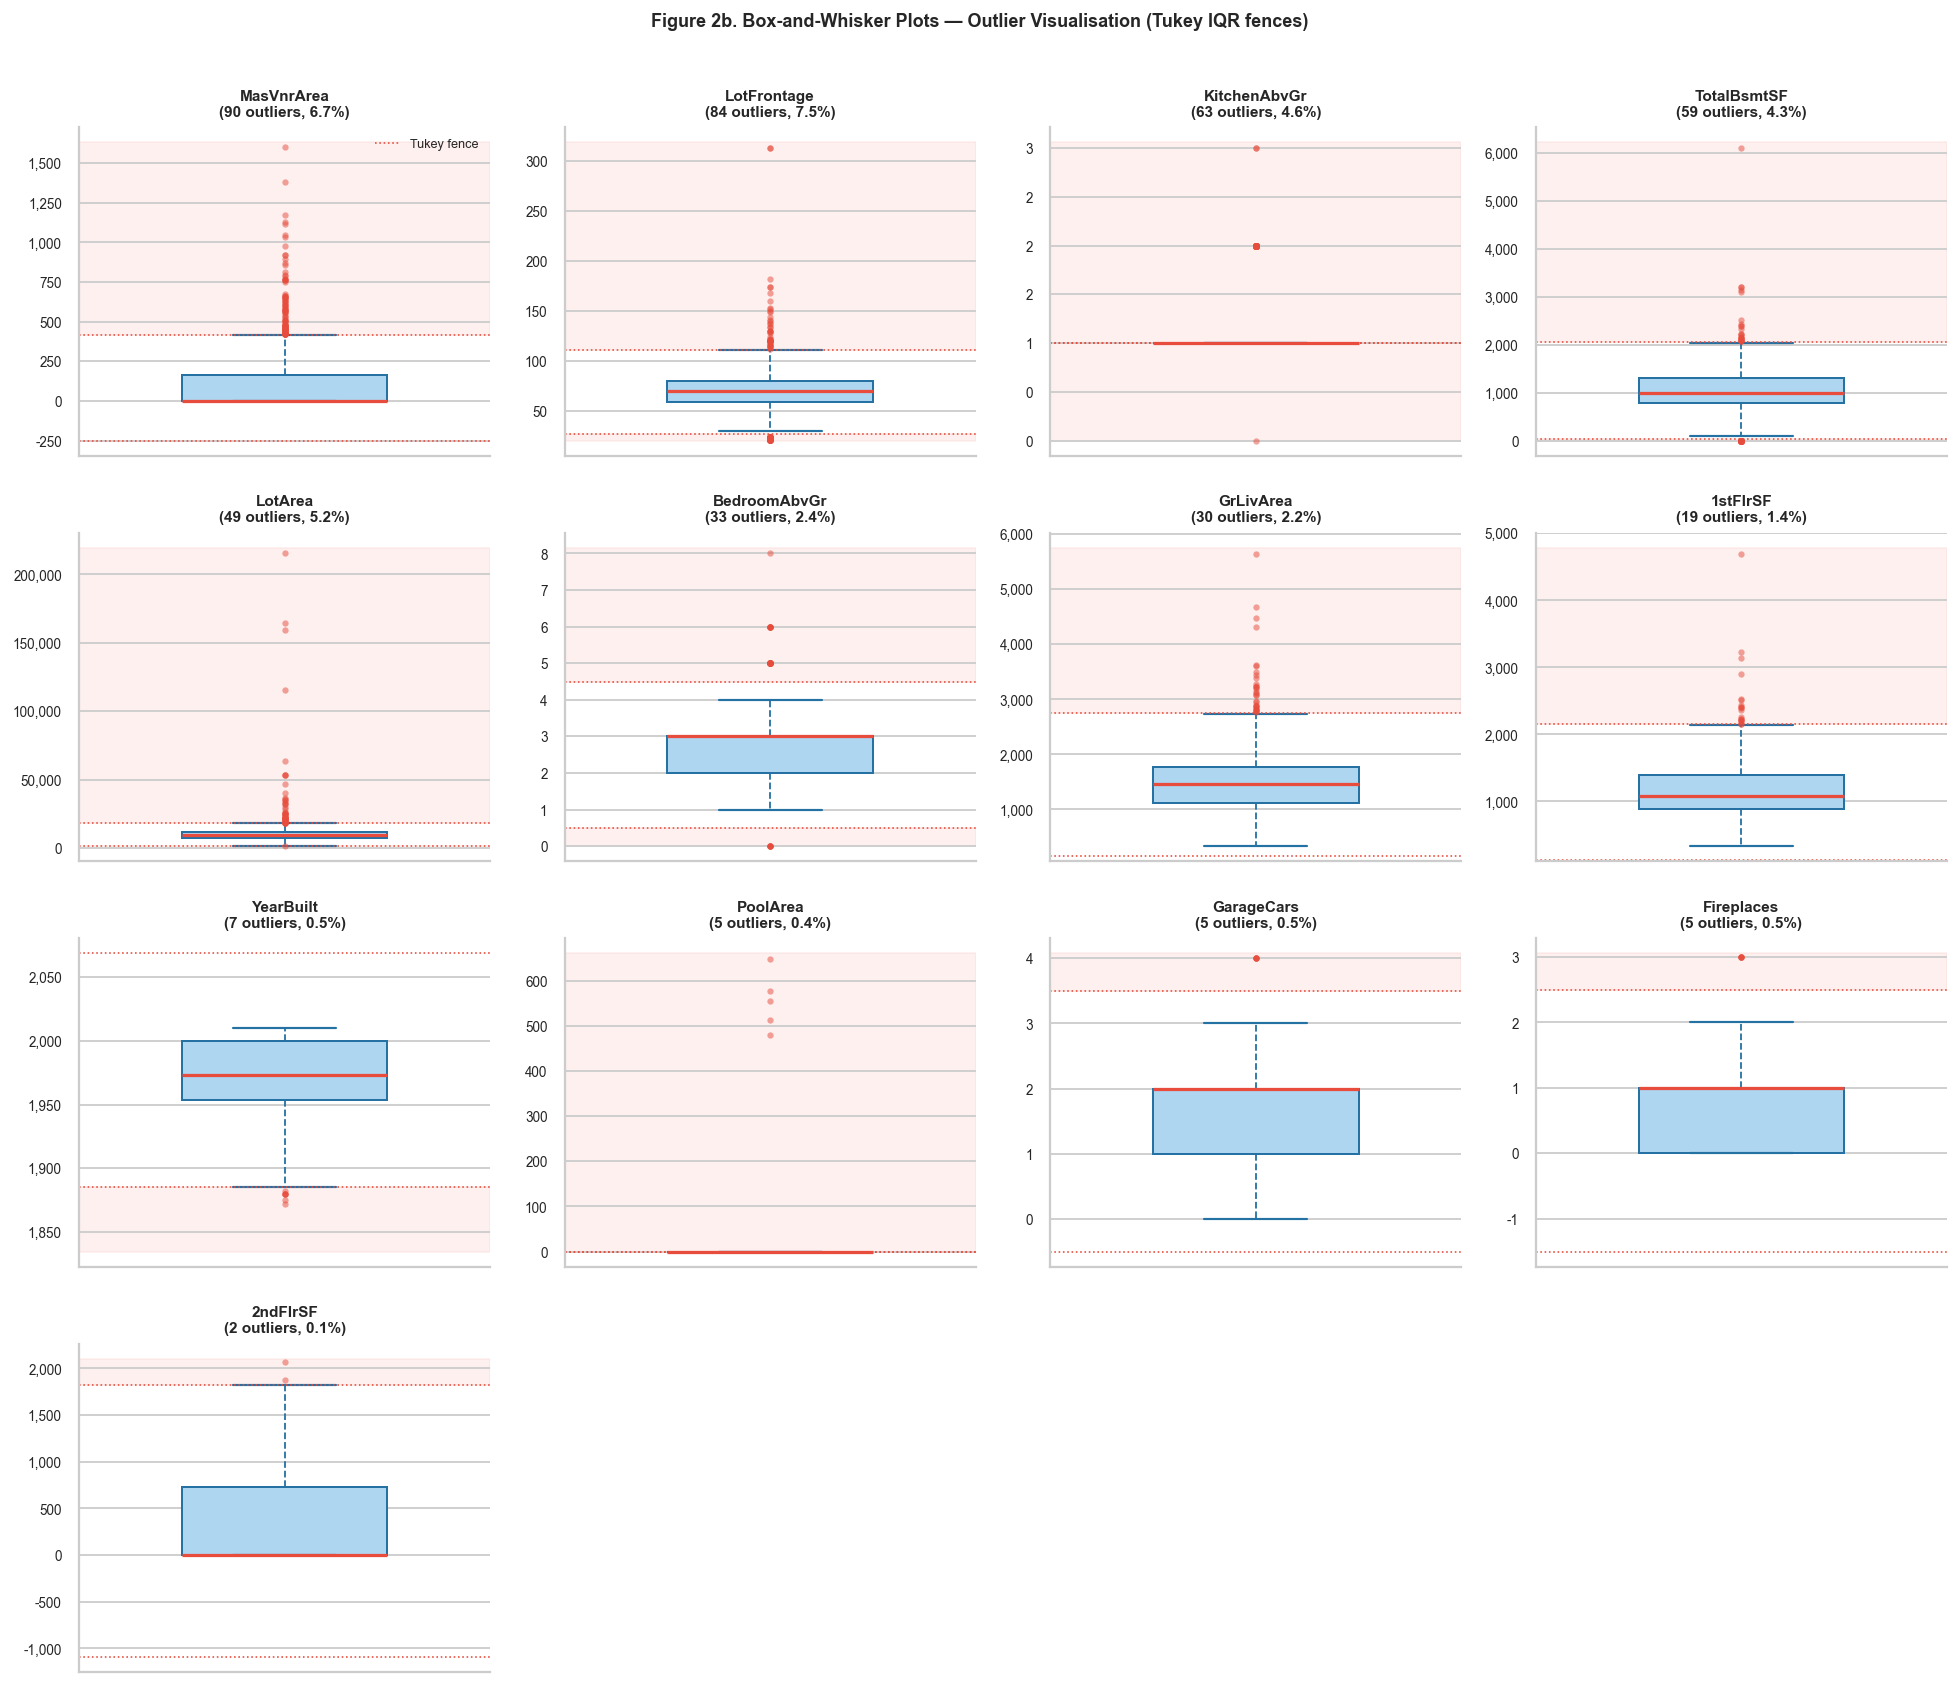

In [8]:
# ── Outlier detection via IQR fencing ─────────────────────────────────────────
# The IQR method (Tukey fences) is a non-parametric, distribution-agnostic
# technique well-suited to skewed real-estate data.
# Fence definition:  lower = Q1 - 1.5·IQR,  upper = Q3 + 1.5·IQR

outlier_report = {}
for col in num_cols:
    series = df_raw[col].dropna()
    Q1, Q3 = series.quantile(0.25), series.quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    n_out = ((series < lower) | (series > upper)).sum()
    outlier_report[col] = {
        'lower_fence': round(lower, 2),
        'upper_fence': round(upper, 2),
        'n_outliers' : int(n_out),
        'outlier_%'  : round(n_out / len(series) * 100, 2)
    }

outlier_df = pd.DataFrame(outlier_report).T.sort_values('n_outliers', ascending=False)
print('=== IQR outlier report ===')
print(outlier_df[outlier_df['n_outliers'] > 0].to_string())

# ── Box-and-whisker plots — outlier visualisation ─────────────────────────────
# Select only columns that have outliers (n_outliers > 0) for plotting.
# Flier points represent values beyond the Tukey fences.
outlier_cols = outlier_df[outlier_df['n_outliers'] > 0].index.tolist()

n_cols_box = 4
n_rows_box = int(np.ceil(len(outlier_cols) / n_cols_box))

fig, axes = plt.subplots(n_rows_box, n_cols_box,
                         figsize=(n_cols_box * 3.8, n_rows_box * 3.2))
axes = axes.flatten()

for i, col in enumerate(outlier_cols):
    ax = axes[i]
    data = df_raw[col].dropna()
    Q1, Q3 = data.quantile(0.25), data.quantile(0.75)
    IQR_val = Q3 - Q1
    lower_f, upper_f = Q1 - 1.5 * IQR_val, Q3 + 1.5 * IQR_val
    n_out = int(outlier_report[col]['n_outliers'])

    bp = ax.boxplot(
        data,
        vert=True,
        patch_artist=True,
        widths=0.5,
        boxprops=dict(facecolor='#AED6F1', color='#2471A3', linewidth=1.1),
        medianprops=dict(color='#E74C3C', linewidth=1.8),
        whiskerprops=dict(color='#2471A3', linewidth=1.0, linestyle='--'),
        capprops=dict(color='#2471A3', linewidth=1.2),
        flierprops=dict(marker='o', markersize=3.5, alpha=0.5,
                        markerfacecolor='#E74C3C', markeredgecolor='none'),
    )
    # Shade the outlier region above the upper fence
    y_max = data.max()
    if y_max > upper_f:
        ax.axhspan(upper_f, y_max * 1.02, color='#FADBD8', alpha=0.4, zorder=0)
    if data.min() < lower_f:
        ax.axhspan(data.min() * 0.98, lower_f, color='#FADBD8', alpha=0.4, zorder=0)

    ax.axhline(upper_f, color='#E74C3C', lw=0.9, linestyle=':', label='Tukey fence')
    ax.axhline(lower_f, color='#E74C3C', lw=0.9, linestyle=':')
    ax.set_title(f'{col}\n({n_out} outliers, {outlier_report[col]["outlier_%"]:.1f}%)',
                 fontsize=8.5, fontweight='bold')
    ax.set_xticks([])
    ax.tick_params(axis='y', labelsize=7.5)
    ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
    if i == 0:
        ax.legend(fontsize=7, frameon=False)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Figure 2b. Box-and-Whisker Plots — Outlier Visualisation (Tukey IQR fences)',
             fontsize=10, fontweight='bold', y=1.01)
plt.tight_layout(h_pad=2.0, w_pad=1.2)
plt.savefig(FIGURES_DIR / 'fig2b_boxplots_outliers.png', bbox_inches='tight')
plt.show()


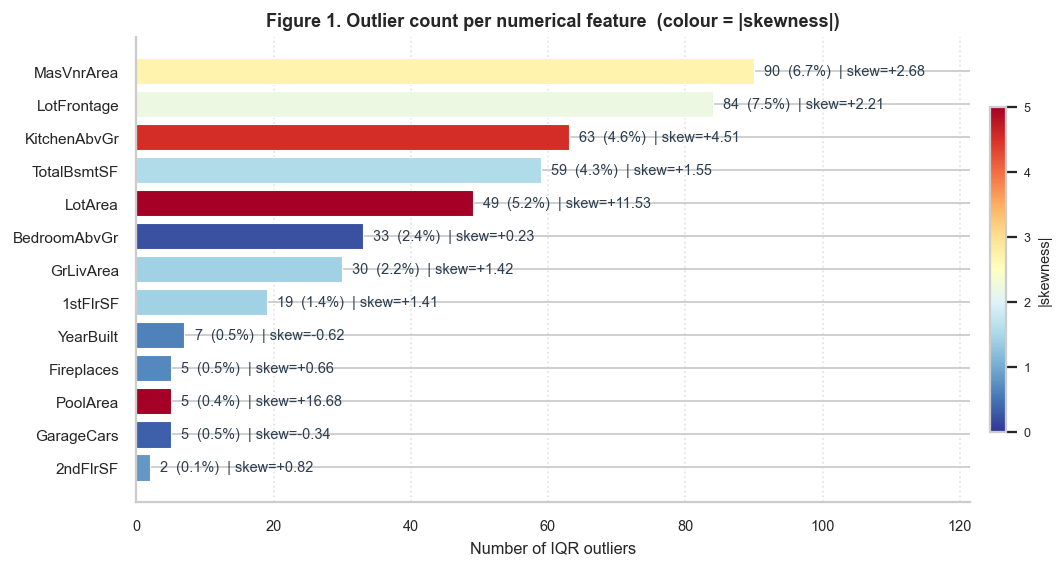

In [9]:
# ── Outlier summary bar chart ─────────────────────────────────────────────────
# Compact alternative to multiple box plots: one bar per variable showing the
# number of IQR outliers, coloured by skewness magnitude. Reveals which
# features are most affected by extreme values at a single glance.

# Reuse outlier_df from the previous cell (must contain n_outliers and outlier_%)
# Skewness is computed alongside to colour the bars.
out_data = outlier_df[outlier_df['n_outliers'] > 0].copy()
out_data['skew'] = df_raw[out_data.index].skew()
out_data = out_data.sort_values('n_outliers', ascending=True)   # ascending → largest on top

# Colour scale: |skew| → red intensity (symmetric = blue, very skewed = red)
norm = plt.Normalize(vmin=0, vmax=5)
cmap = plt.cm.RdYlBu_r
colors = [cmap(norm(abs(s))) for s in out_data['skew']]

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(out_data.index, out_data['n_outliers'],
               color=colors, edgecolor='white', linewidth=0.6)

# Annotate each bar with count and outlier %
for bar, n, pct, sk in zip(bars, out_data['n_outliers'],
                            out_data['outlier_%'], out_data['skew']):
    ax.text(bar.get_width() + 1.5, bar.get_y() + bar.get_height() / 2,
            f'{int(n)}  ({pct:.1f}%)  | skew={sk:+.2f}',
            va='center', fontsize=8, color='#2c3e50')

ax.set_xlabel('Number of IQR outliers', fontsize=9)
ax.set_xlim(0, out_data['n_outliers'].max() * 1.35)
ax.set_title('Figure 1. Outlier count per numerical feature  (colour = |skewness|)',
             fontsize=10, fontweight='bold')
ax.tick_params(axis='y', labelsize=8.5)
ax.tick_params(axis='x', labelsize=8)
ax.grid(axis='x', linestyle=':', alpha=0.5)
ax.set_axisbelow(True)

# Colour bar legend
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, shrink=0.7, pad=0.02)
cbar.set_label('|skewness|', fontsize=8)
cbar.ax.tick_params(labelsize=7)

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig1_outlier_barchart.png', bbox_inches='tight', dpi=150)
plt.show()

### 2.2 Correlation Analysis

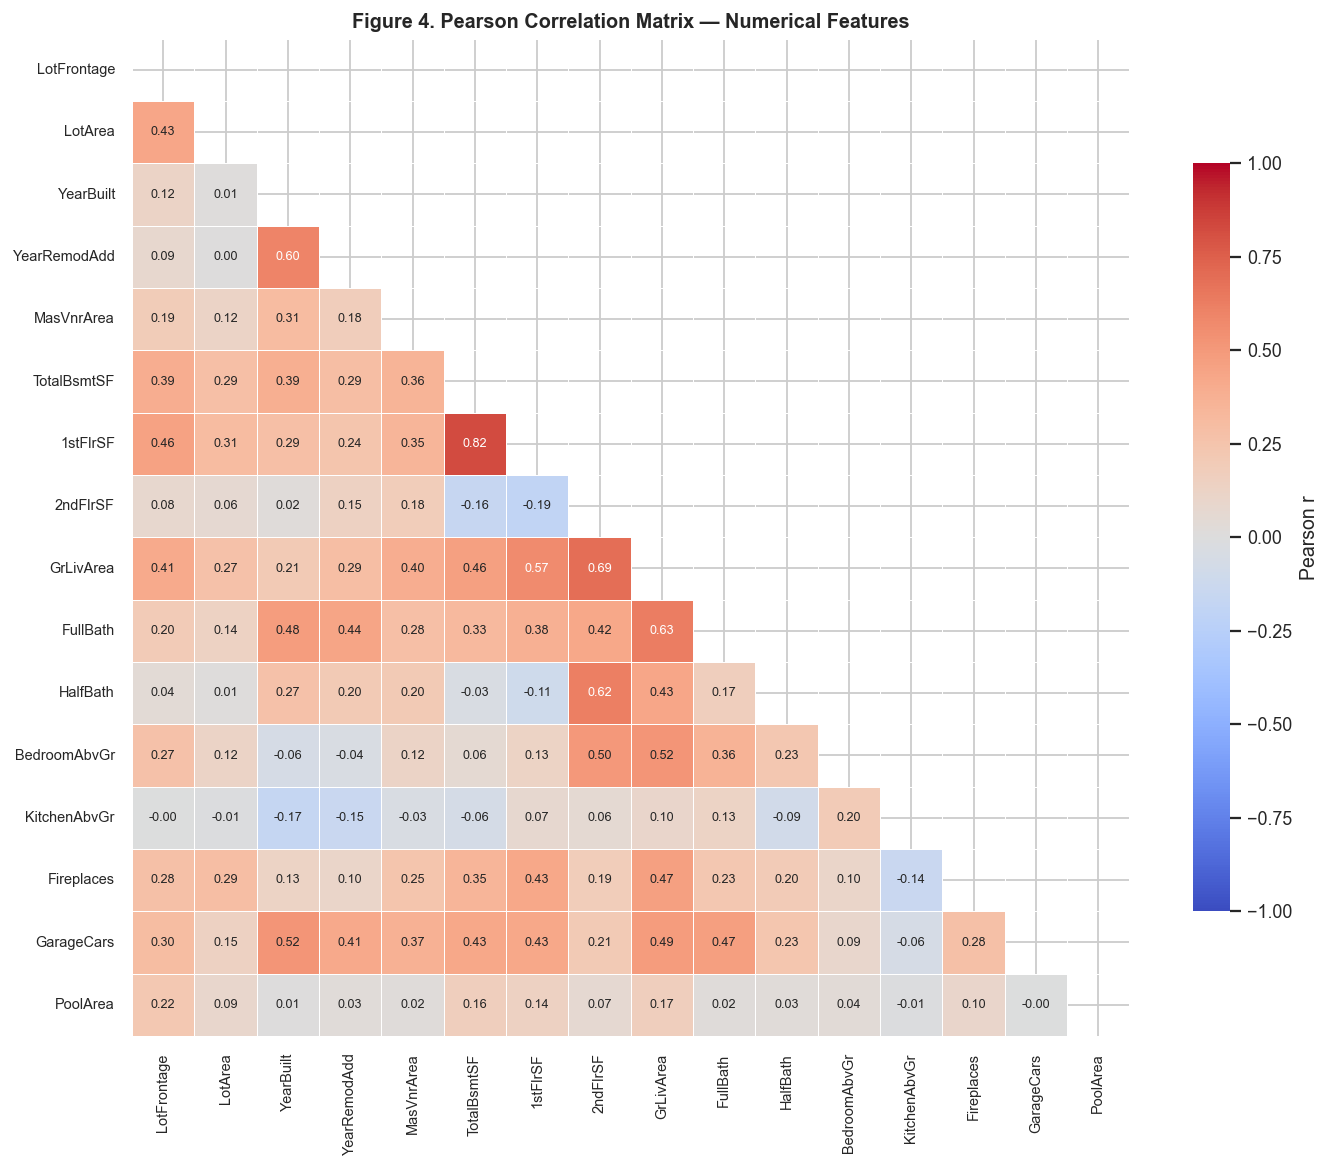

=== Highly correlated pairs (|r| > 0.80) ===
Feature A   Feature B      |r|
 1stFlrSF TotalBsmtSF 0.823016


In [10]:

# ── Pearson correlation matrix ─────────────────────────────────────────────────
corr_matrix = df_raw[num_cols].corr()

fig, ax = plt.subplots(figsize=(11, 9))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix, mask=mask,
    annot=True, fmt='.2f',
    cmap='coolwarm', center=0, vmin=-1, vmax=1,
    linewidths=0.4, linecolor='white',
    square=True, ax=ax,
    annot_kws={'size': 7},
    cbar_kws={'shrink': 0.75, 'label': 'Pearson r'}
)
ax.set_title('Figure 4. Pearson Correlation Matrix — Numerical Features',
             fontsize=11, fontweight='bold')
ax.tick_params(axis='both', labelsize=8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig3_correlation_matrix.png', bbox_inches='tight')
plt.show()

high_corr = (
    corr_matrix.abs()
    .where(np.tril(np.ones(corr_matrix.shape), k=-1).astype(bool))
    .stack().reset_index()
)
high_corr.columns = ['Feature A', 'Feature B', '|r|']
print('=== Highly correlated pairs (|r| > 0.80) ===')
print(high_corr[high_corr['|r|'] > 0.80].sort_values('|r|', ascending=False).to_string(index=False))


### 2.3 Visual Inspection

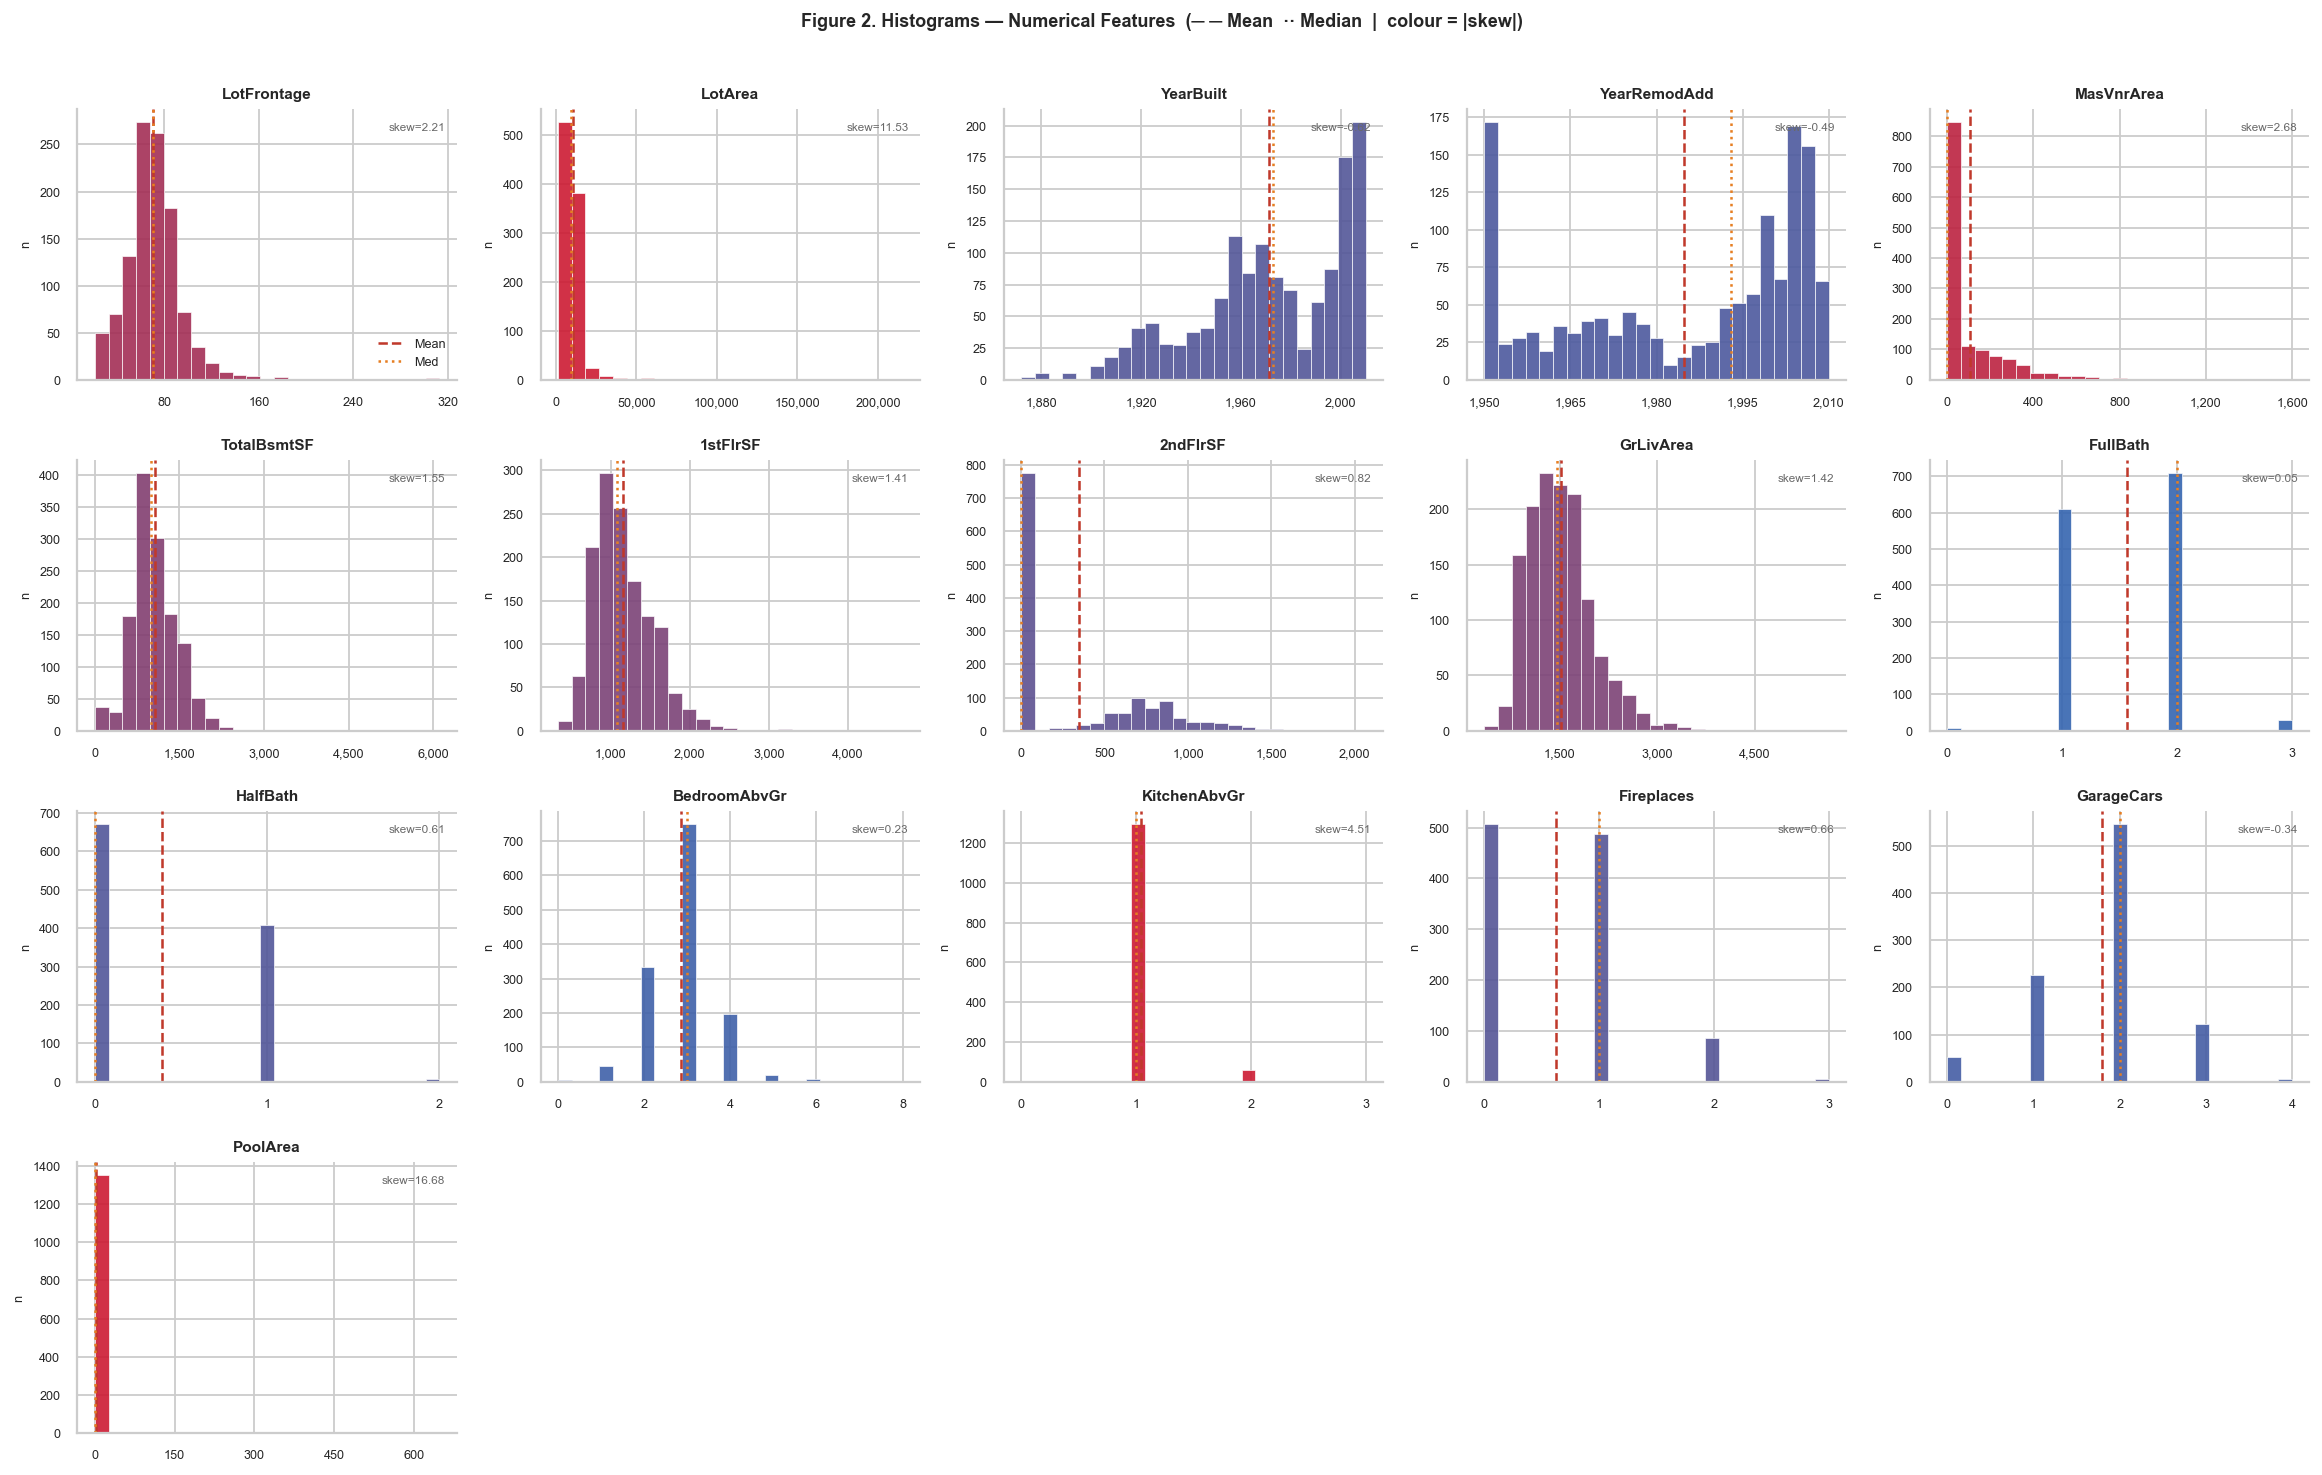

=== Skewness (|skew| > 1 → strong asymmetry) ===
PoolArea        16.684
LotArea         11.535
KitchenAbvGr     4.512
MasVnrArea       2.683
LotFrontage      2.205
TotalBsmtSF      1.553
GrLivArea        1.422
1stFlrSF         1.408
2ndFlrSF         0.820
Fireplaces       0.664
HalfBath         0.609
BedroomAbvGr     0.232
FullBath         0.047
GarageCars      -0.343
YearRemodAdd    -0.493
YearBuilt       -0.623


In [11]:

# ── Histograms — numerical features ───────────────────────────────────────────
plot_num = [c for c in num_cols]

skew_vals = df_raw[plot_num].skew()

# Color bars by absolute skewness: blue (symmetric) → red (skewed)
def skew_color(s):
    a = min(abs(s) / 3.0, 1.0)
    r, g, b = 0.2 + 0.6*a, 0.4 - 0.3*a, 0.7 - 0.5*a
    return (r, g, b)

n_cols = 5
n_rows = int(np.ceil(len(plot_num) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 2.8))
axes = axes.flatten()

for i, col in enumerate(plot_num):
    ax = axes[i]
    data = df_raw[col].dropna()
    skew = skew_vals[col]
    ax.hist(data, bins=25, color=skew_color(skew), edgecolor='white', linewidth=0.4, alpha=0.9)
    ax.axvline(data.mean(),   color='#c0392b', lw=1.4, linestyle='--', label='Mean')
    ax.axvline(data.median(), color='#e67e22', lw=1.4, linestyle=':',  label='Med')
    ax.set_title(col, fontsize=8.5, fontweight='bold')
    ax.set_ylabel('n', fontsize=7)
    ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True, nbins=5))
    ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
    ax.tick_params(labelsize=7)
    ax.text(0.97, 0.95, f'skew={skew:.2f}', transform=ax.transAxes,
            fontsize=6.5, ha='right', va='top', color='dimgray')
    if i == 0:
        ax.legend(fontsize=7, frameon=False)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Figure 2. Histograms — Numerical Features  (─ ─ Mean  ·· Median  |  colour = |skew|)',
             fontsize=10, fontweight='bold', y=1.01)
plt.tight_layout(h_pad=1.5, w_pad=1.0)
plt.savefig(FIGURES_DIR / 'fig2_histograms.png', bbox_inches='tight')
plt.show()

skew_summary = df_raw[plot_num].skew().sort_values(ascending=False)
print('=== Skewness (|skew| > 1 → strong asymmetry) ===')
print(skew_summary.round(3).to_string())


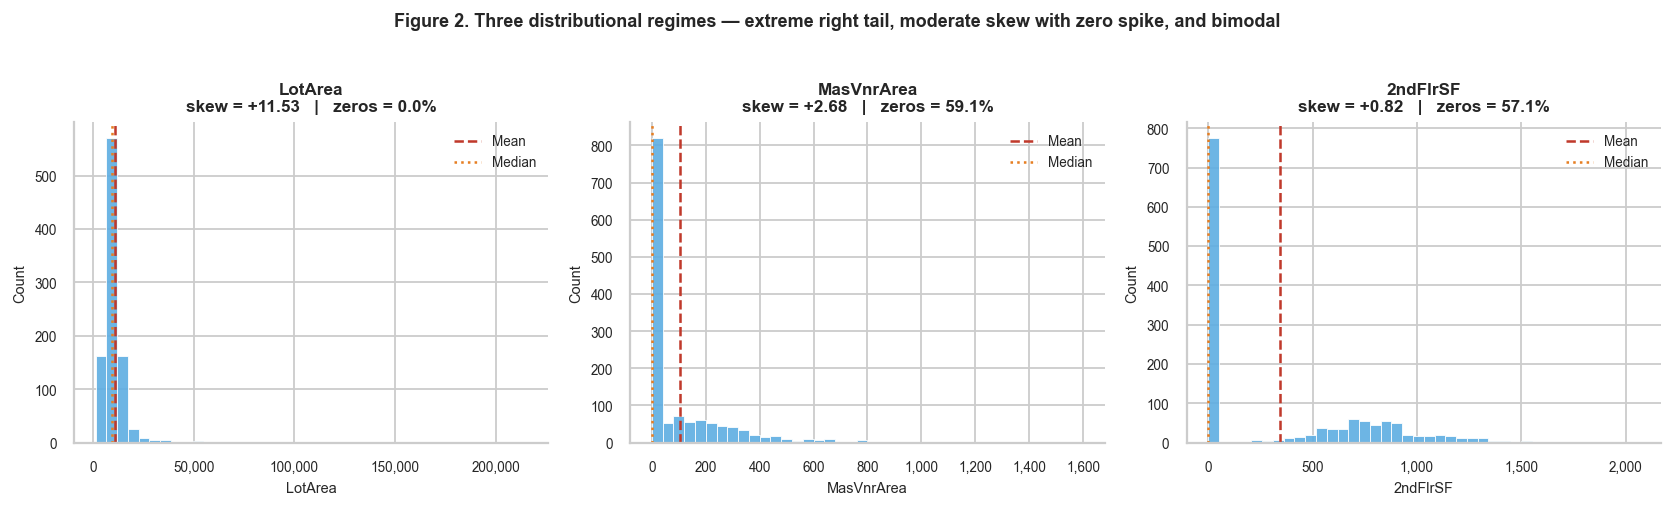

In [12]:
# ── Key non-normality patterns: histogram triptych ────────────────────────────
# Three histograms chosen to illustrate three distinct distributional regimes
# uncovered by the EDA, each requiring a different curation strategy.
#
#   LotArea    → extreme right tail (skew = 11.5)
#   MasVnrArea → moderate right tail with zero spike
#   2ndFlrSF   → bimodal: structural zeros (57.1%) + near-normal upper mode

key_features = ['LotArea', 'MasVnrArea', '2ndFlrSF']

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))

for ax, col in zip(axes, key_features):
    data = df_raw[col].dropna()
    skew = data.skew()
    pct_zero = (data == 0).mean() * 100

    ax.hist(data, bins=40, color='#5DADE2', edgecolor='white', linewidth=0.5, alpha=0.9)
    ax.axvline(data.mean(),   color='#c0392b', lw=1.4, linestyle='--', label='Mean')
    ax.axvline(data.median(), color='#e67e22', lw=1.4, linestyle=':',  label='Median')

    ax.set_title(f'{col}\nskew = {skew:+.2f}   |   zeros = {pct_zero:.1f}%',
                 fontsize=9.5, fontweight='bold')
    ax.set_xlabel(col, fontsize=8)
    ax.set_ylabel('Count', fontsize=8)
    ax.tick_params(labelsize=7.5)
    ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
    ax.legend(fontsize=7.5, frameon=False)

fig.suptitle('Figure 2. Three distributional regimes — extreme right tail, moderate skew with zero spike, and bimodal',
             fontsize=10, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig2_histograms_key.png', bbox_inches='tight', dpi=150)
plt.show()

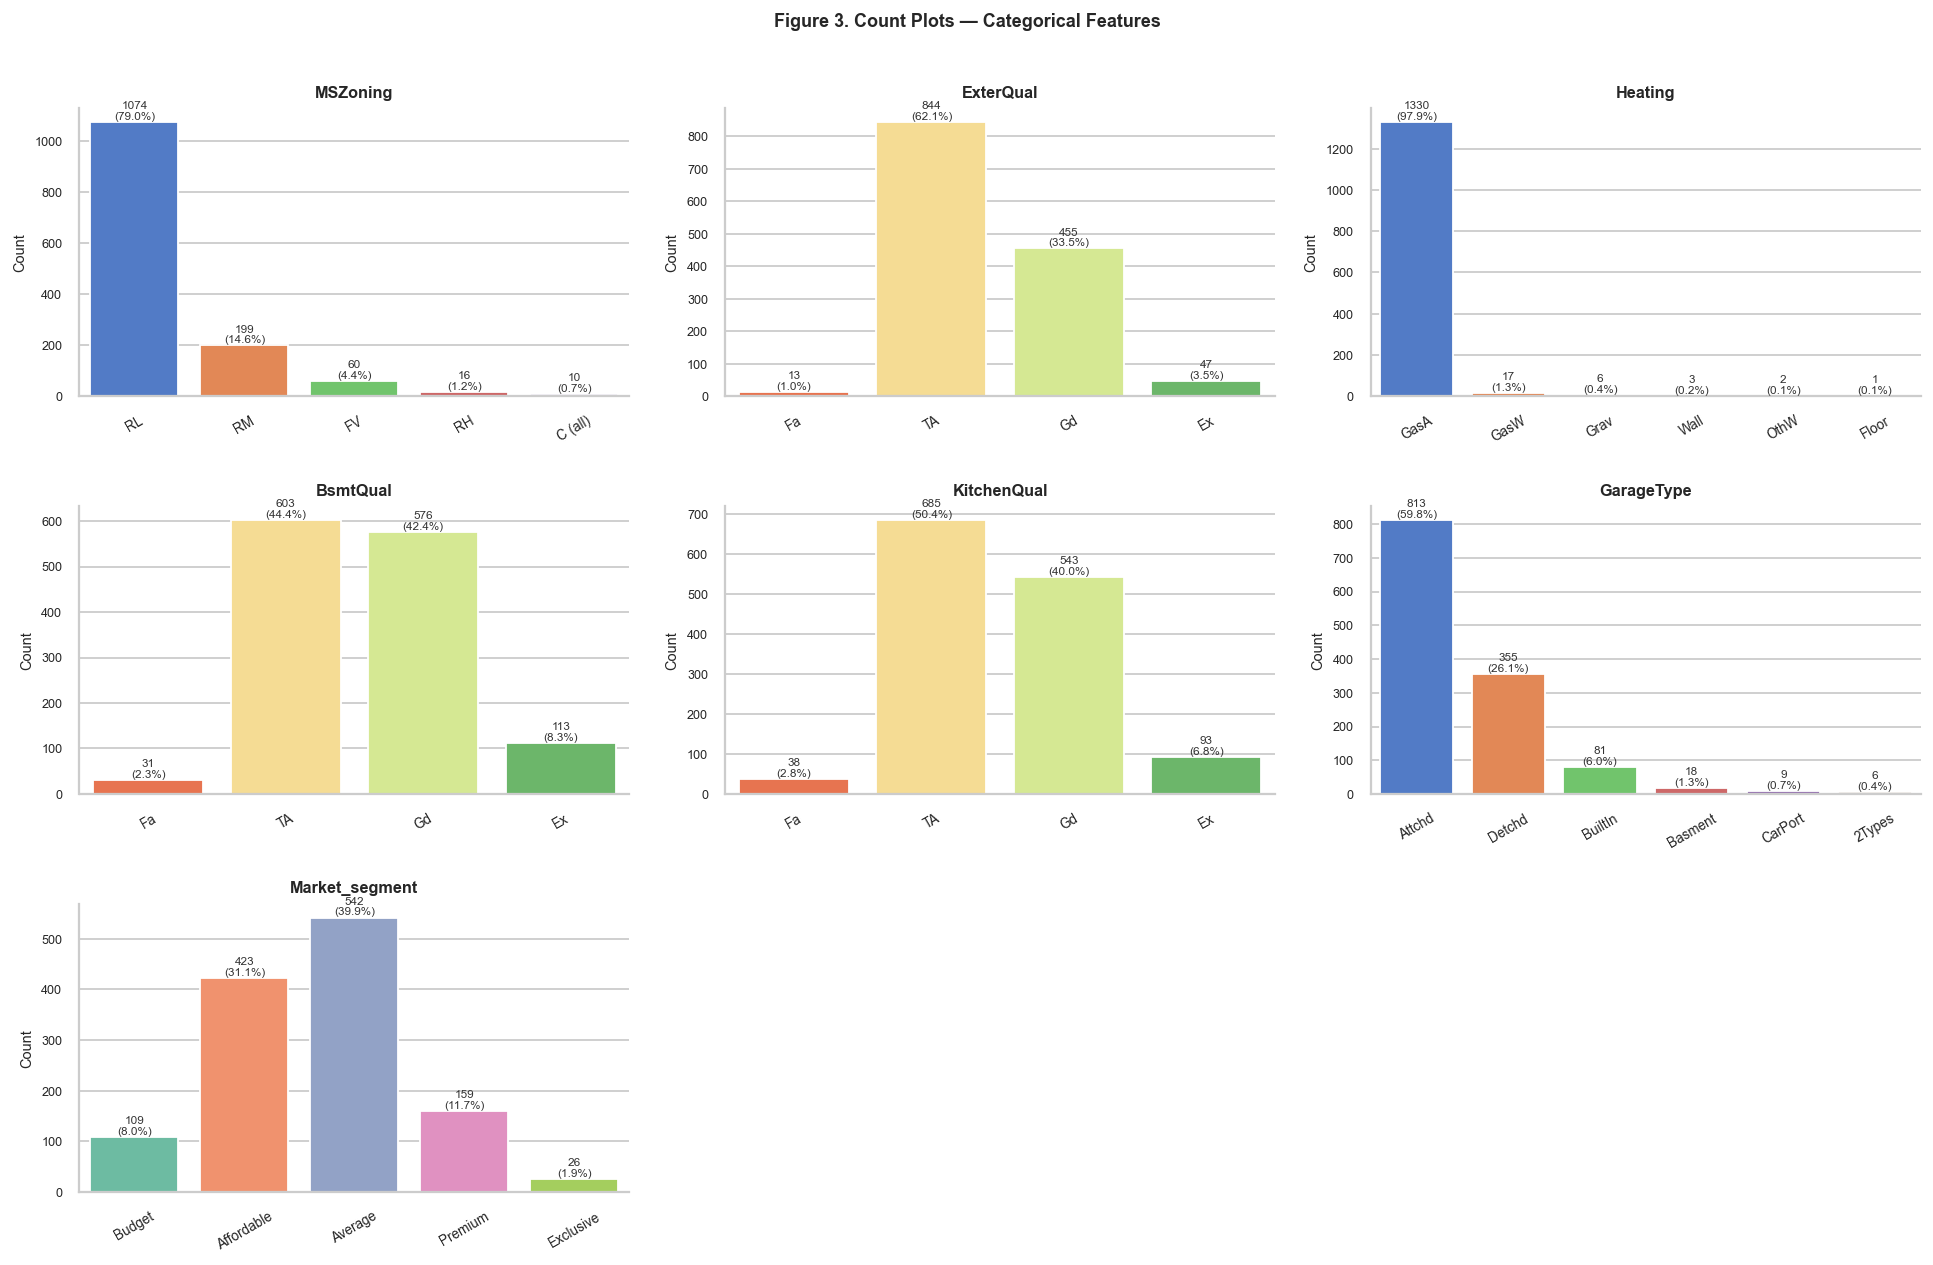

In [13]:

# ── Count plots — categorical features ────────────────────────────────────────
cat_cols  = ['MSZoning', 'ExterQual', 'Heating',
             'BsmtQual', 'KitchenQual', 'GarageType', 'Market_segment']
qual_cols = {'ExterQual', 'BsmtQual', 'KitchenQual'}

n_cols = 3
n_rows = int(np.ceil(len(cat_cols) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows * 3.2))
axes = axes.flatten()
total = len(df_raw)

for i, col in enumerate(cat_cols):
    ax = axes[i]
    if col in qual_cols:
        order = [o for o in QUALITY_ORDER if o in df_raw[col].dropna().unique()]
        palette = 'RdYlGn'
    elif col == 'Market_segment':
        order = [s for s in SEG_ORDER if s in df_raw[col].dropna().unique()]
        palette = 'Set2'
    else:
        order = df_raw[col].value_counts().index.tolist()
        palette = 'muted'

    sns.countplot(data=df_raw, x=col, order=order, palette=palette, ax=ax,
                  saturation=0.85)
    ax.set_title(col, fontsize=9, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('Count', fontsize=8)
    ax.tick_params(axis='x', rotation=30, labelsize=7.5)
    ax.tick_params(axis='y', labelsize=7)

    for bar in ax.patches:
        h = bar.get_height()
        if h > 0:
            pct = h / total * 100
            ax.text(bar.get_x() + bar.get_width() / 2, h + 1,
                    f'{int(h)}\n({pct:.1f}%)',
                    ha='center', va='bottom', fontsize=6.5, color='#333333',
                    linespacing=1.1)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Figure 3. Count Plots — Categorical Features', fontsize=10, fontweight='bold', y=1.01)
plt.tight_layout(h_pad=2.0, w_pad=1.5)
plt.savefig(FIGURES_DIR / 'fig_count_plots_unused.png', bbox_inches='tight')
plt.show()


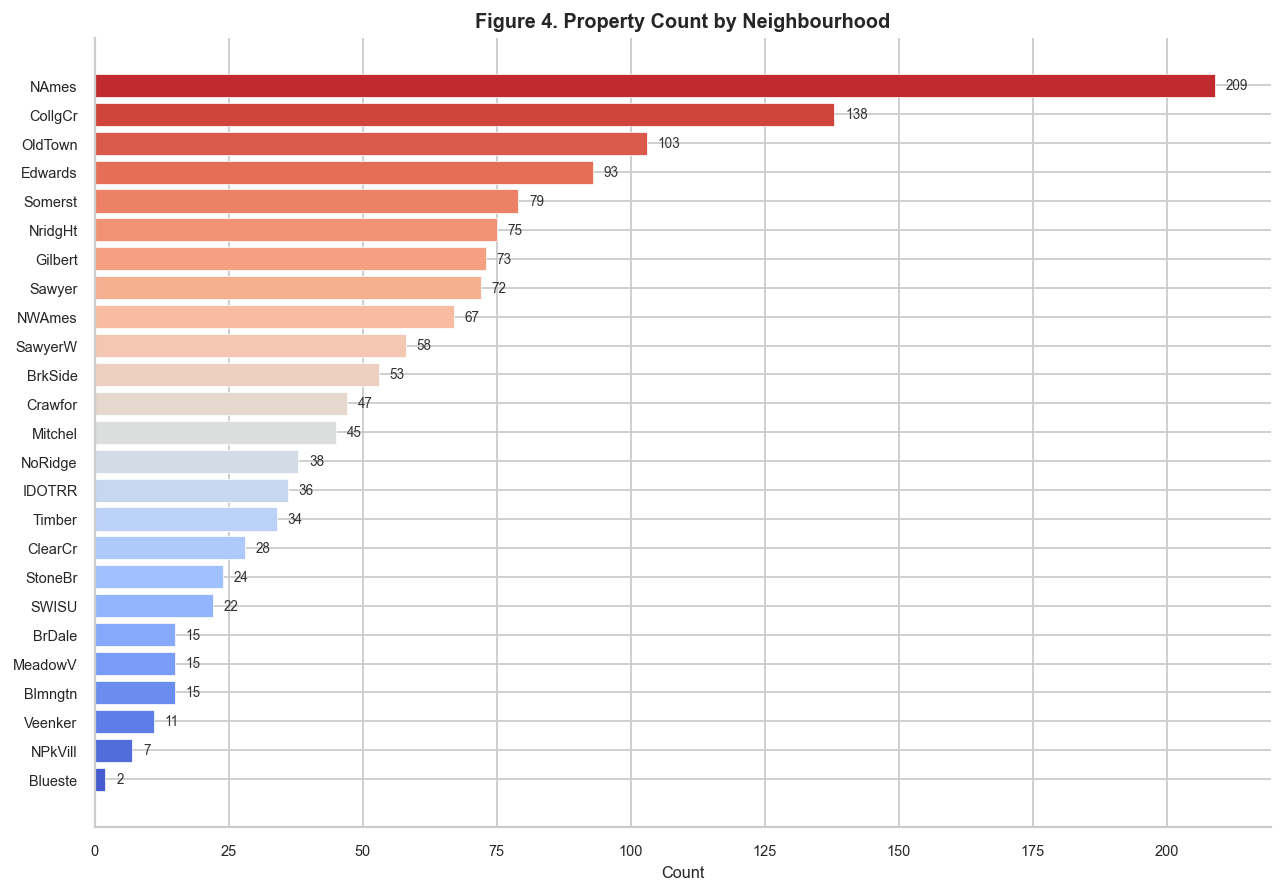

In [14]:

# ── Count plot — Neighborhood (horizontal bar for readability) ─────────────────
counts = df_raw['Neighborhood'].value_counts()
colors = sns.color_palette('coolwarm_r', len(counts))

fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(counts.index, counts.values, color=colors, edgecolor='white', linewidth=0.4)
ax.set_xlabel('Count', fontsize=9)
ax.set_title('Figure 4. Property Count by Neighbourhood', fontsize=11, fontweight='bold')
ax.tick_params(axis='y', labelsize=8)
ax.tick_params(axis='x', labelsize=8)
ax.invert_yaxis()

for bar, val in zip(bars, counts.values):
    ax.text(val + 2, bar.get_y() + bar.get_height() / 2,
            str(val), va='center', fontsize=7.5, color='#333333')

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig4_neighbourhood.png', bbox_inches='tight')
plt.show()


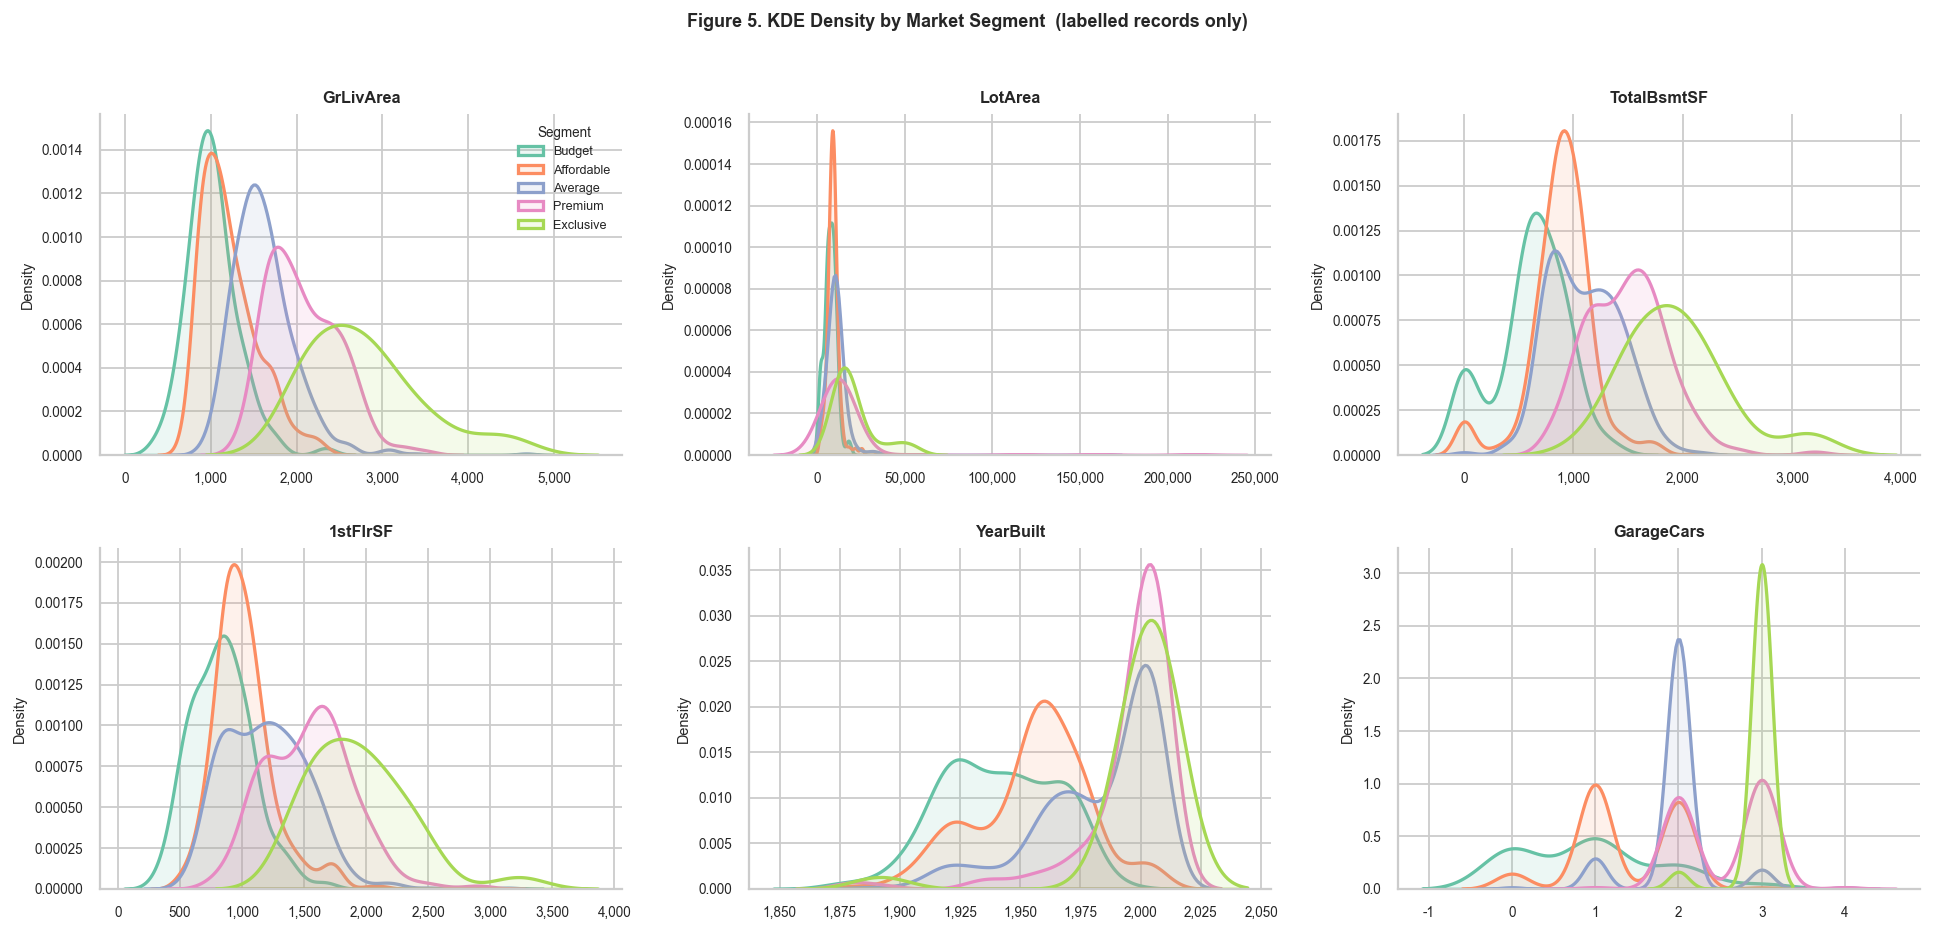

In [15]:

# ── Density (KDE) plots — continuous features by Market Segment ────────────────
df_labelled = df_raw.dropna(subset=['Market_segment'])
kde_features = ['GrLivArea', 'LotArea', 'TotalBsmtSF', '1stFlrSF', 'YearBuilt', 'GarageCars']

n_cols = 3
n_rows = int(np.ceil(len(kde_features) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows * 3.5))
axes = axes.flatten()

for i, col in enumerate(kde_features):
    ax = axes[i]
    for seg in SEG_ORDER:
        subset = df_labelled.loc[df_labelled['Market_segment'] == seg, col].dropna()
        if len(subset) > 5:
            sns.kdeplot(subset, ax=ax, label=seg, color=SEG_PALETTE[seg],
                        linewidth=1.8, fill=True, alpha=0.12)
    ax.set_title(col, fontsize=9, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('Density', fontsize=8)
    ax.tick_params(labelsize=7.5)
    ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
    if i == 0:
        ax.legend(fontsize=7, title='Segment', title_fontsize=7.5, frameon=False)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Figure 5. KDE Density by Market Segment  (labelled records only)',
             fontsize=10, fontweight='bold', y=1.02)
plt.tight_layout(h_pad=2.0, w_pad=1.5)
plt.savefig(FIGURES_DIR / 'fig5_kde_by_segment.png', bbox_inches='tight')
plt.show()


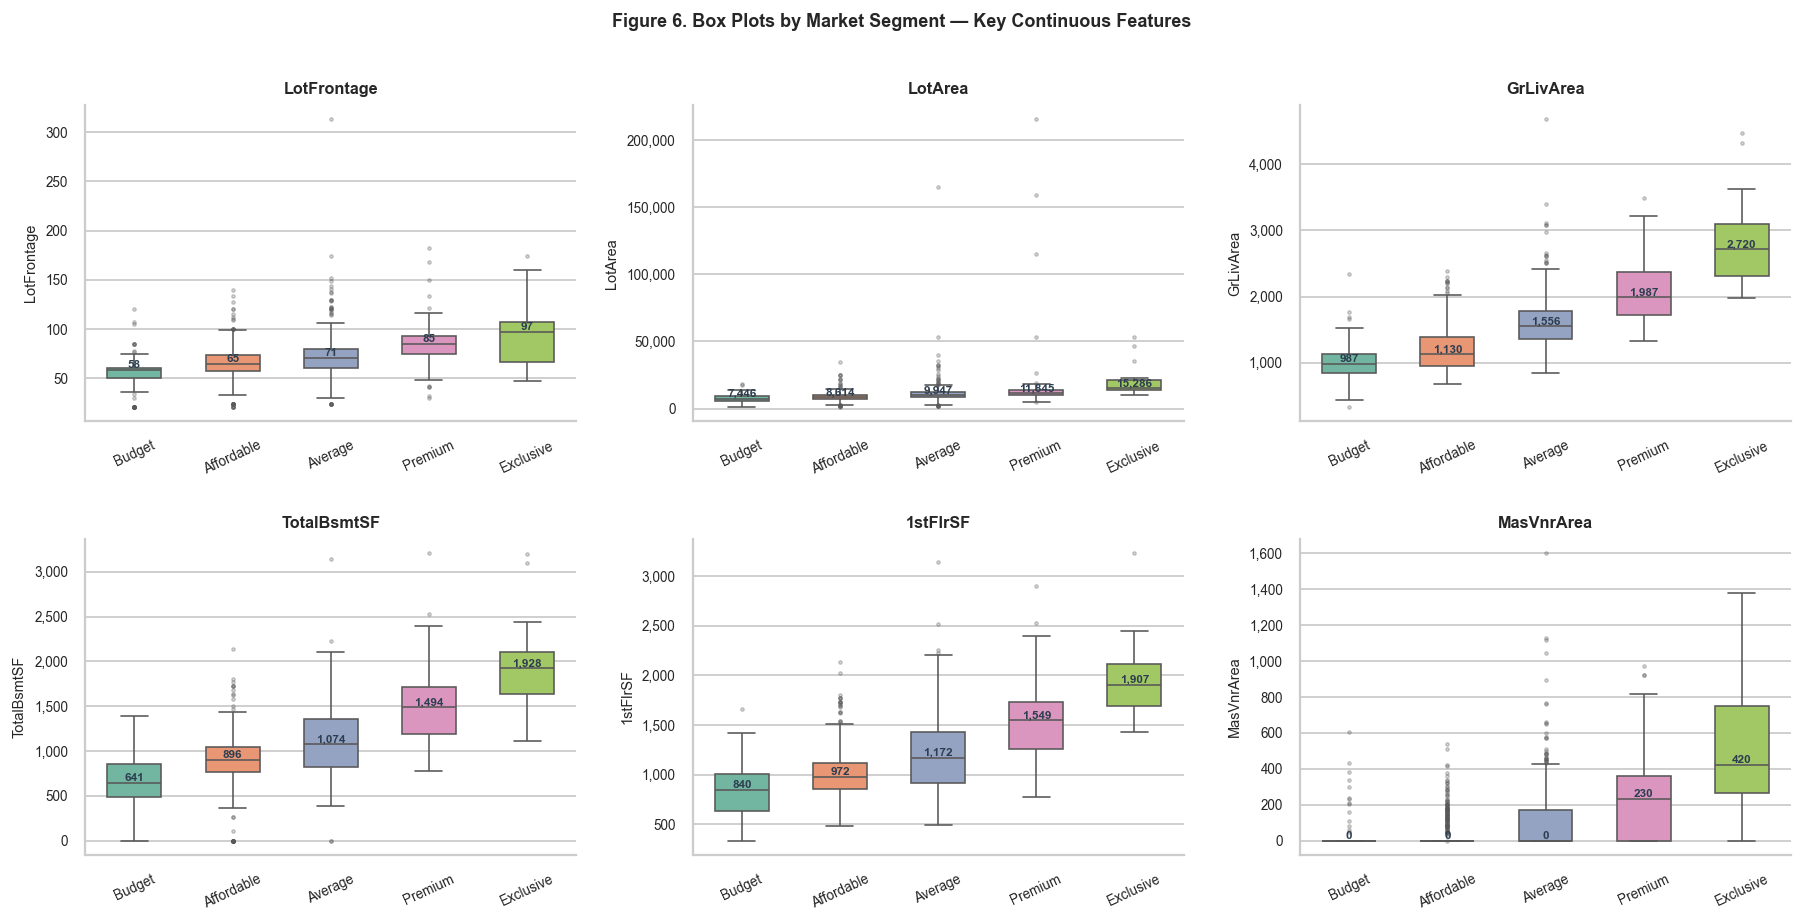

In [16]:

# ── Box plots — outlier visualisation by Market Segment ───────────────────────
box_features = ['LotFrontage', 'LotArea', 'GrLivArea', 'TotalBsmtSF', '1stFlrSF', 'MasVnrArea']

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes = axes.flatten()

for i, col in enumerate(box_features):
    ax = axes[i]
    data = df_raw[[col, 'Market_segment']].dropna(subset=[col])
    valid_order = [s for s in SEG_ORDER if s in data['Market_segment'].dropna().unique()]
    sns.boxplot(
        data=data, x='Market_segment', y=col,
        order=valid_order, palette='Set2', ax=ax,
        width=0.55, linewidth=0.9,
        showfliers=True,
        flierprops=dict(marker='.', markersize=3, alpha=0.4, color='#7f8c8d')
    )
    # Overlay median value label
    for j, seg in enumerate(valid_order):
        med = data.loc[data['Market_segment'] == seg, col].median()
        ax.text(j, med, f'{med:,.0f}', ha='center', va='bottom',
                fontsize=6.5, color='#2c3e50', fontweight='bold')
    ax.set_title(col, fontsize=9, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel(col, fontsize=8)
    ax.tick_params(axis='x', rotation=25, labelsize=7.5)
    ax.tick_params(axis='y', labelsize=7.5)
    ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

fig.suptitle('Figure 6. Box Plots by Market Segment — Key Continuous Features',
             fontsize=10, fontweight='bold', y=1.01)
plt.tight_layout(h_pad=2.0, w_pad=1.5)
plt.savefig(FIGURES_DIR / 'fig6_boxplots_by_segment.png', bbox_inches='tight')
plt.show()


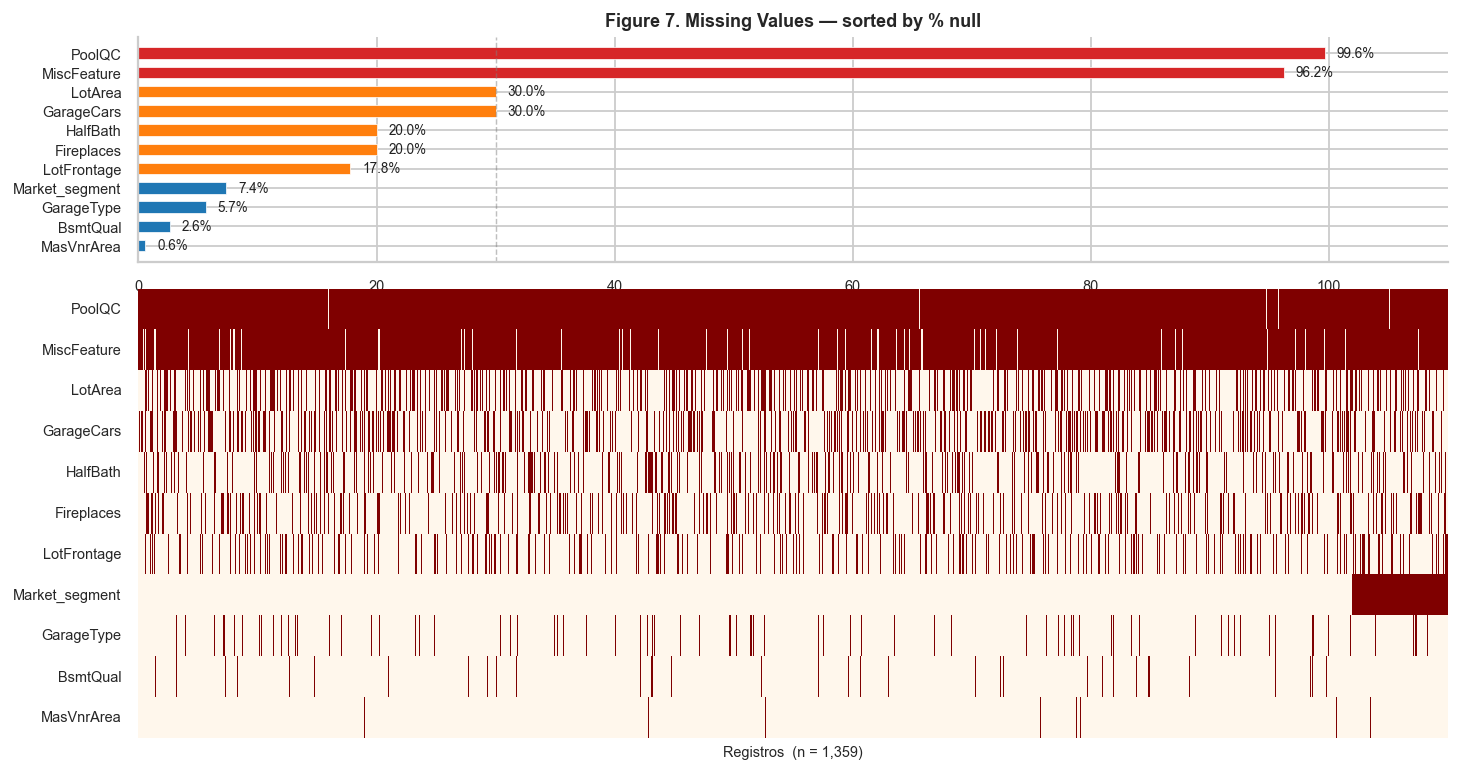

In [17]:

# ── Missing value analysis — bar chart + heatmap ─────────────────────────────
null_pct = (df_raw.isnull().sum() / len(df_raw) * 100)
null_pct = null_pct[null_pct > 0].sort_values(ascending=False)   # solo columnas con nulos, orden desc
sorted_cols = null_pct.index.tolist()

fig, (ax_bar, ax_heat) = plt.subplots(
    2, 1, figsize=(13, 7),
    gridspec_kw={'height_ratios': [1, 2], 'hspace': 0.08}
)

# ── Panel superior: barras horizontales ordenadas ─────────────────────────────
colors_bar = ['#d62728' if p > 50 else '#ff7f0e' if p > 10 else '#1f77b4' for p in null_pct.values]
bars = ax_bar.barh(null_pct.index, null_pct.values, color=colors_bar,
                   edgecolor='white', linewidth=0.4, height=0.6)
ax_bar.set_xlim(0, 110)
ax_bar.set_xlabel('% Missing', fontsize=8)
ax_bar.set_title('Figure 7. Missing Values — sorted by % null', fontsize=10, fontweight='bold')
ax_bar.invert_yaxis()
ax_bar.tick_params(labelsize=8)
ax_bar.axvline(30, color='grey', lw=0.8, linestyle='--', alpha=0.5)
for bar, val in zip(bars, null_pct.values):
    ax_bar.text(val + 1, bar.get_y() + bar.get_height() / 2,
                f'{val:.1f}%', va='center', fontsize=7.5, color='#222222')

# ── Panel inferior: heatmap de patrón espacial ────────────────────────────────
sns.heatmap(
    df_raw[sorted_cols].isnull().T,
    cbar=False,
    yticklabels=True,
    xticklabels=False,
    cmap='OrRd',
    ax=ax_heat,
    linewidths=0,
)
ax_heat.set_xlabel(f'Registros  (n = {len(df_raw):,})', fontsize=8)
ax_heat.set_ylabel('')
ax_heat.tick_params(axis='y', labelsize=8)

plt.savefig(FIGURES_DIR / 'fig7_missing_heatmap.png', bbox_inches='tight')
plt.show()


---
## Step 3 — Data Curation

Curation is treated as a systematic sequence: (1) data selection, (2) duplicate removal, (3) transcription-error rectification, (4) inconsistent-value correction, (5) missing-value handling, and (6) outlier treatment.

Two design principles govern this step:

1. **The target `Market_segment` is never modified.** The 100 unlabelled records are preserved for the labelling notebook.
2. **Labelled and unlabelled records are split at the start.** All imputation statistics (medians, modes, rare-level lists) are derived from the labelled subset only, then applied identically to the unlabelled subset. This prevents information leakage from the unlabelled hold-out into the fitted curation.


In [18]:
# ── Curation setup ────────────────────────────────────────────────────────────
# A working copy is created so the raw DataFrame remains available for comparison.
# A log dictionary tracks every transformation for the audit trail.
# Output paths are centralised for reproducibility.


CURATED_CSV = DATASETS_DIR / 'homes_curated.csv'

df_work = df_raw.copy()

curation_log = {
    'initial_rows_total'      : len(df_work),
    'initial_rows_labelled'   : df_work['Market_segment'].notna().sum(),
    'initial_rows_unlabelled' : df_work['Market_segment'].isna().sum(),
    'initial_cols'            : df_work.shape[1],
    'actions'                 : []
}

def log_action(name, df_labelled, df_unlabelled, cols, detail=''):
    curation_log['actions'].append({
        'step'                 : name,
        'labelled_rows'        : len(df_labelled),
        'unlabelled_rows'      : len(df_unlabelled),
        'cols'                 : cols,
        'detail'               : detail
    })

print(f'Starting curation with {len(df_work)} rows × {df_work.shape[1]} columns')
print(f'  Labelled:   {curation_log["initial_rows_labelled"]}')
print(f'  Unlabelled: {curation_log["initial_rows_unlabelled"]}')

Starting curation with 1359 rows × 27 columns
  Labelled:   1259
  Unlabelled: 100


### 3.1 Labelled / Unlabelled Split

The first curation operation is to separate labelled from unlabelled records. Every subsequent decision (imputation statistics, rare-level thresholds, outlier fences) is derived from the labelled subset and then applied to both subsets. This keeps the unlabelled hold-out epistemically disjoint from the training pipeline.

In [19]:
# ── 3.1 Labelled / Unlabelled Split ───────────────────────────────────────────
df_lab   = df_raw[df_raw['Market_segment'].notna()].copy().reset_index(drop=True)
df_unlab = df_raw[df_raw['Market_segment'].isna()].copy().reset_index(drop=True)

print(f'Labelled:   {len(df_lab):4d} rows')
print(f'Unlabelled: {len(df_unlab):4d} rows')
log_action('3.1 Split labelled/unlabelled', df_lab, df_unlab, df_lab.shape[1],
           detail='Separated before any curation to prevent leakage')

Labelled:   1259 rows
Unlabelled:  100 rows


### 3.2 Data Selection

In [20]:
# ── 3.2 Data Selection ────────────────────────────────────────────────────────
# Selection means choosing a subset of relevant, high-quality data.
# Columns dropped based on EDA findings:
#   - Id:          identifier, not a feature
#   - PoolQC:      99.6% structurally absent → no discriminative signal
#   - MiscFeature: 96.2% null with heterogeneous rare categories → noise
#   - LotArea:     30.0% missing → imputation would distort variance;
#                  the column is discarded instead
#   - GarageCars:  30.0% missing and largely redundant with GarageType
#                  (which already encodes the presence/absence of a garage)
#   - TotalBsmtSF: redundant with 1stFlrSF (r = 0.82); the basement footprint
#                  is largely bounded by the first-floor footprint. 1stFlrSF
#                  is retained because it has no missing values and is more
#                  discriminative (represents actual living area).

COLS_TO_DROP = ['Id', 'PoolQC', 'MiscFeature', 'LotArea', 'GarageCars', 'TotalBsmtSF']

df_lab   = df_lab.drop(columns=COLS_TO_DROP)
df_unlab = df_unlab.drop(columns=COLS_TO_DROP)

log_action('3.2 Data Selection', df_lab, df_unlab, df_lab.shape[1],
           detail=f'Dropped: {COLS_TO_DROP}')
print(f'Dropped {len(COLS_TO_DROP)} columns → {df_lab.shape[1]} remaining')

Dropped 6 columns → 21 remaining


### 3.3 Duplicate Removal

In [21]:
# ── 3.3 Duplicate Removal ─────────────────────────────────────────────────────
# Exact matching is used for identical rows (removal strategy).
# Duplicate detection is performed within each subset independently.
# Cross-subset duplicates are intentionally preserved: an unlabelled record that
# happens to match a labelled one is a legitimate candidate for labelling.

n_dup_lab   = df_lab.duplicated().sum()
n_dup_unlab = df_unlab.duplicated().sum()

if n_dup_lab > 0:
    df_lab = df_lab.drop_duplicates().reset_index(drop=True)

print(f'Labelled duplicates removed:   {n_dup_lab}')
print(f'Unlabelled duplicates removed: {n_dup_unlab}')
log_action('3.3 Duplicate Removal', df_lab, df_unlab, df_lab.shape[1],
           detail=f'{n_dup_lab} labelled + {n_dup_unlab} unlabelled duplicates removed')

Labelled duplicates removed:   2
Unlabelled duplicates removed: 0


### 3.4 Row Deletion for Excessive Missingness

In [22]:
# ── 3.4 Row Deletion for Excessive Missingness ────────────────────────────────
# After dropping the five non-recoverable columns (PoolQC, MiscFeature, LotArea,
# GarageCars, TotalBsmtSF), most rows have at most one or two missing values
# that can be imputed faithfully. A small number of rows, however, accumulate
# three or more missing values across distinct mechanisms (acquisition gaps +
# structural absences). Rows with too many simultaneous gaps become largely
# synthetic after imputation and contribute more noise than signal.
#
# Threshold: drop rows with >= 3 missing values across the remaining feature
# columns. This affects ~1.6% of the labelled subset, well within the 2%
# tolerance. The unlabelled subset is left untouched.

MISSING_THRESHOLD = 3

r0 = len(df_lab)
feature_cols = [c for c in df_lab.columns if c != 'Market_segment']

n_missing_per_row = df_lab[feature_cols].isnull().sum(axis=1)
mask_keep = n_missing_per_row < MISSING_THRESHOLD
df_lab = df_lab[mask_keep].reset_index(drop=True)

n_dropped = r0 - len(df_lab)
print(f'Rows dropped (>= {MISSING_THRESHOLD} missing): {n_dropped} ({n_dropped/r0*100:.2f}%)')
print(f'Labelled rows remaining: {len(df_lab)}')

log_action('3.4 Row Deletion (excessive missingness)', df_lab, df_unlab, df_lab.shape[1],
           detail=f'{n_dropped} labelled rows dropped (>= {MISSING_THRESHOLD} missing values)')

Rows dropped (>= 3 missing): 20 (1.59%)
Labelled rows remaining: 1237


### 3.5 Transcription Errors

In [23]:
# ── 3.5 Transcription Errors ──────────────────────────────────────────────────
# Transcription errors are typing mistakes made when the dataset was built:
# e.g. "Somerst" vs "Somerset", or the same neighbourhood recorded with two
# slight spelling variants. Since such errors can repeat systematically, a
# frequency-based filter would miss them. We therefore flag every pair of
# values within a column whose string similarity is >= 0.80, regardless of
# how often each value appears, and leave the final judgement to the analyst.

from difflib import SequenceMatcher

SIMILARITY_THRESHOLD = 0.80

def similarity(a, b):
    return SequenceMatcher(None, a.lower(), b.lower()).ratio()

def audit_transcription(df, label):
    issues = []
    for col in df.select_dtypes(include=["object", "string"]).columns:
        counts = df[col].dropna().astype(str).value_counts()
        vals = counts.index.tolist()
        for i, a in enumerate(vals):
            for b in vals[i + 1:]:
                sim = similarity(a, b)
                if sim >= SIMILARITY_THRESHOLD:
                    # Order the pair so the rarer value is reported first for clarity
                    if counts[a] <= counts[b]:
                        rare_val, common_val = a, b
                    else:
                        rare_val, common_val = b, a
                    issues.append(
                        f"[{label}] {col}: {rare_val!r} ({int(counts[rare_val])}x) "
                        f"vs {common_val!r} ({int(counts[common_val])}x) "
                        f"-> similarity {sim:.2f}"
                    )
    return issues

issues = audit_transcription(df_lab, "labelled")

if not issues:
    print("No similar value pairs detected.")
else:
    print(f"{len(issues)} similar pair(s) flagged for review:")
    for msg in issues:
        print(f"  {msg}")
    print()
    print("Note: high similarity does not imply a transcription error; the "
          "analyst must decide case by case (e.g. NAmes vs NWAmes are "
          "legitimate distinct neighbourhoods despite high string overlap).")

log_action("3.5 Transcription Errors", df_lab, df_unlab, df_lab.shape[1],
           detail=f"{len(issues)} similar pair(s) flagged")

2 similar pair(s) flagged for review:
  [labelled] Neighborhood: 'NWAmes' (57x) vs 'NAmes' (192x) -> similarity 0.91
  [labelled] Neighborhood: 'SawyerW' (55x) vs 'Sawyer' (68x) -> similarity 0.92

Note: high similarity does not imply a transcription error; the analyst must decide case by case (e.g. NAmes vs NWAmes are legitimate distinct neighbourhoods despite high string overlap).


### 3.6 Inconsistent Values

In [24]:
# ── 3.6 Inconsistent Values ───────────────────────────────────────────────────
# Domain-bound sanity checks. Failures are reported but not auto-corrected:
# a professional pipeline would raise an issue for human review rather than
# silently modify the data. The comprehensive rule set is formalised with
# Great Expectations in Step 4.

def run_sanity_checks(df, label):
    checks = {
        'YearBuilt in [1800, 2025]' : df['YearBuilt'].between(1800, 2025).all(),
        'YearRemodAdd >= YearBuilt' : (df['YearRemodAdd'] >= df['YearBuilt']).all(),
        'FullBath >= 0'             : (df['FullBath'] >= 0).all(),
        'BedroomAbvGr >= 0'         : (df['BedroomAbvGr'] >= 0).all(),
        'GrLivArea > 0'             : (df['GrLivArea'] > 0).all(),
    }
    print(f'--- {label} ---')
    failures = [n for n, ok in checks.items() if not ok]
    for name, ok in checks.items():
        print(f'  [{"PASS" if ok else "FAIL"}] {name}')
    return failures

fail_lab   = run_sanity_checks(df_lab, 'labelled')
fail_unlab = run_sanity_checks(df_unlab, 'unlabelled')

log_action('3.6 Inconsistent Values', df_lab, df_unlab, df_lab.shape[1],
           detail=f'Failures — labelled: {fail_lab}, unlabelled: {fail_unlab}')

--- labelled ---
  [PASS] YearBuilt in [1800, 2025]
  [PASS] YearRemodAdd >= YearBuilt
  [PASS] FullBath >= 0
  [PASS] BedroomAbvGr >= 0
  [PASS] GrLivArea > 0
--- unlabelled ---
  [PASS] YearBuilt in [1800, 2025]
  [PASS] YearRemodAdd >= YearBuilt
  [PASS] FullBath >= 0
  [PASS] BedroomAbvGr >= 0
  [PASS] GrLivArea > 0


### 3.7 Missing Value Handling

In [25]:
# ── 3.7 Missing Value Handling ────────────────────────────────────────────────
# Three strategies are considered: deletion, imputation, and flagging.
# The EDA showed missingness follows two mechanisms (structural vs. acquisition
# gap), so imputation is tailored per variable.
#
# All imputation statistics are computed from the labelled subset and applied
# identically to both subsets, so the unlabelled records do not influence the
# fitted values. Market_segment is never imputed.
#
# Imputation choices per variable:
#   BsmtQual, GarageType  → "None"                    (structural absence)
#   MasVnrArea            → 0                         (structural absence: no veneer)
#   LotFrontage           → median by Neighborhood    (varies strongly by district)
#   HalfBath, Fireplaces  → mode (=0)                 (discrete counts, bulk at 0)

# ─ Statistics fitted on the labelled subset
lf_medians_by_hood = df_lab.groupby('Neighborhood')['LotFrontage'].median()
lf_global_median   = df_lab['LotFrontage'].median()
halfbath_mode      = int(df_lab['HalfBath'].mode()[0])
fireplaces_mode    = int(df_lab['Fireplaces'].mode()[0])

def apply_imputation(df):
    out = df.copy()
    # Structural absences
    out['BsmtQual']   = out['BsmtQual'].fillna('None')
    out['GarageType'] = out['GarageType'].fillna('None')
    out['MasVnrArea'] = out['MasVnrArea'].fillna(0)
    # LotFrontage by neighborhood (fallback to global median for hoods unseen
    # in the labelled subset)
    out['LotFrontage'] = out.apply(
        lambda r: (lf_medians_by_hood.get(r['Neighborhood'], lf_global_median)
                   if pd.isna(r['LotFrontage']) else r['LotFrontage']),
        axis=1
    )
    # Discrete counts
    out['HalfBath']   = out['HalfBath'].fillna(halfbath_mode).astype(int)
    out['Fireplaces'] = out['Fireplaces'].fillna(fireplaces_mode).astype(int)
    return out

df_lab   = apply_imputation(df_lab)
df_unlab = apply_imputation(df_unlab)

# ─ Verify: no non-target nulls remain; Market_segment preserved
for label, d in [('labelled', df_lab), ('unlabelled', df_unlab)]:
    non_target = d.drop(columns=['Market_segment']).isnull().sum().sum()
    assert non_target == 0, f'{label} has {non_target} residual nulls'

assert df_lab['Market_segment'].notna().all(), 'Labelled subset has NaN in target'
assert df_unlab['Market_segment'].isna().all(), 'Unlabelled subset has non-NaN in target'

log_action('3.7 Missing Value Handling', df_lab, df_unlab, df_lab.shape[1],
           detail='Fitted on labelled; structural → None/0; LotFrontage → median by Neighborhood')
print('All non-target missing values handled in both subsets.')

All non-target missing values handled in both subsets.


### 3.8 Rare Categorical Levels

In [26]:
# ── 3.8 Rare Categorical Levels ───────────────────────────────────────────────
# Two distinct collapses are applied:
#
#   - Neighborhood with fewer than MIN_N_HOOD records in the labelled subset
#     → "Other". This is a purely statistical collapse: small neighborhoods
#     cannot support per-group estimates reliably.
#
#   - GarageType values 'CarPort' and '2Types' → "Atypical". These refer to
#     genuinely unusual garage configurations (non-standard structure or
#     multiple types), so the label reflects the category, not the count.
#
# Both mappings are derived from the labelled subset only and then applied to
# unlabelled records so that the two subsets share the same value space.

MIN_N_HOOD       = 20
ATYPICAL_GARAGES = ['CarPort', '2Types']

# Rare neighborhoods fitted on labelled
hood_counts_lab = df_lab['Neighborhood'].value_counts()
RARE_HOODS      = hood_counts_lab[hood_counts_lab < MIN_N_HOOD].index.tolist()

def collapse_rare(df):
    out = df.copy()
    out['Neighborhood'] = out['Neighborhood'].where(~out['Neighborhood'].isin(RARE_HOODS), 'Other')
    out['GarageType']   = out['GarageType'].where(~out['GarageType'].isin(ATYPICAL_GARAGES), 'Atypical')
    return out

df_lab   = collapse_rare(df_lab)
# df_unlab = collapse_rare(df_unlab)

print(f'Rare neighborhoods collapsed to "Other":  {RARE_HOODS}')
print(f'Atypical garage types collapsed to "Atypical": {ATYPICAL_GARAGES}')
log_action('3.8 Rare Categorical Levels', df_lab, df_unlab, df_lab.shape[1],
           detail=f'Neighborhood rare→Other ({len(RARE_HOODS)}); GarageType rare→Atypical')

Rare neighborhoods collapsed to "Other":  ['Blmngtn', 'MeadowV', 'BrDale', 'Veenker', 'NPkVill', 'Blueste']
Atypical garage types collapsed to "Atypical": ['CarPort', '2Types']


### 3.9 Outlier Treatment

In [27]:
# ── 3.9 Outlier Treatment (labelled subset only) ──────────────────────────────
# Decision per variable follows the EDA diagnosis, based on kurtosis and
# outlier share:
#   - kurt > 7 with many outliers (>5%)  → cap k=3  (heavy tails but many points)
#   - else                               → cap k=1.5 (standard Tukey fences)
#
# No rows are eliminated: every outlier-prone feature has enough mass in the
# tails to make capping more appropriate than row-level removal.
#
# The unlabelled subset is left untouched so the unlabelled hold-out preserves
# its original distribution.

def iqr_fences(series, k=1.5):
    Q1, Q3 = series.quantile(0.25), series.quantile(0.75)
    IQR = Q3 - Q1
    return Q1 - k * IQR, Q3 + k * IQR

CAP_K15 = ['1stFlrSF', 'GrLivArea', 'KitchenAbvGr',
           'BedroomAbvGr', '2ndFlrSF']
CAP_K30 = ['MasVnrArea', 'LotFrontage']

def cap_column(df, col, k):
    """Clip values to Tukey IQR fences, preserving the original dtype."""
    lo, hi = iqr_fences(df[col], k=k)
    n_cap = ((df[col] < lo) | (df[col] > hi)).sum()
    clipped = df[col].clip(lower=lo, upper=hi)
    # Preserve integer dtype if the source column was integer
    if pd.api.types.is_integer_dtype(df[col]):
        clipped = clipped.round().astype(df[col].dtype)
    df[col] = clipped
    return n_cap, lo, hi

print('=== Capping at k=1.5 (standard) ===')
for col in CAP_K15:
    n_cap, lo, hi = cap_column(df_lab, col, k=1.5)
    print(f'  {col:15s}: {n_cap:4d} values capped to [{lo:.0f}, {hi:.0f}]')

print('\n=== Capping at k=3.0 (heavy-tailed features) ===')
for col in CAP_K30:
    n_cap, lo, hi = cap_column(df_lab, col, k=3.0)
    print(f'  {col:15s}: {n_cap:4d} values capped to [{lo:.0f}, {hi:.0f}]')

log_action('3.9 Outlier Treatment (labelled)', df_lab, df_unlab, df_lab.shape[1],
           detail=f'Capped {len(CAP_K15)} features at k=1.5, {len(CAP_K30)} at k=3.0; 0 rows removed')

=== Capping at k=1.5 (standard) ===
  1stFlrSF       :   16 values capped to [128, 2148]
  GrLivArea      :   28 values capped to [183, 2719]
  KitchenAbvGr   :   55 values capped to [1, 1]
  BedroomAbvGr   :   29 values capped to [0, 4]
  2ndFlrSF       :    2 values capped to [-1092, 1820]

=== Capping at k=3.0 (heavy-tailed features) ===
  MasVnrArea     :   21 values capped to [-498, 664]
  LotFrontage    :   11 values capped to [0, 140]


In [28]:
print(f'Labelled:   {len(df_lab):4d} rows')
print(f'Unlabelled: {len(df_unlab):4d} rows')

Labelled:   1237 rows
Unlabelled:  100 rows


### 3.10 Save Curated Dataset

In [29]:
# ── 3.10 Reassemble the curated dataset ────────────────────────────────────────
df_curated = df_lab

# Second pass of deduplication: imputation and column removal can reveal
# previously hidden duplicates. Three pairs in this dataset differ only in
# columns with complementary NaN patterns (e.g. one row has LotArea = NaN and
# the other has a value; after dropping LotArea they become identical).
# Inspection of these pairs in the raw data shows they share the same
# neighbourhood, year, areas and target label, so they are genuine repeated
# records, not merely similar houses.
n_before_dedup = len(df_curated)
df_curated = df_curated.drop_duplicates().reset_index(drop=True)
n_dedup = n_before_dedup - len(df_curated)
print(f'Post-imputation duplicates removed: {n_dedup}')

# Integrity checks
expected_total = len(df_lab) + len(df_unlab)
assert len(df_curated) <= expected_total, 'Row count exceeds subsets'
assert df_curated.drop(columns=['Market_segment']).isnull().sum().sum() == 0, \
    'Residual nulls in curated dataset'

df_curated.to_csv(CURATED_CSV, index=False)
print(f'Curated dataset: {len(df_curated)} rows × {df_curated.shape[1]} columns')
print(f'  Labelled:   {df_curated["Market_segment"].notna().sum()}')
print(f'  Unlabelled: {df_curated["Market_segment"].isna().sum()}')
print(f'\nSaved to {CURATED_CSV.resolve()}')

Post-imputation duplicates removed: 3
Curated dataset: 1234 rows × 21 columns
  Labelled:   1234
  Unlabelled: 0

Saved to C:\Users\user


---
## Step 4 — Business Rule Definition

This step formalises domain knowledge as testable constraints using Great Expectations. Twelve candidate rules were defined covering five categories — physical bounds, temporal consistency, structural identities, structural coherence, habitability and closed domains. Six rules were selected for implementation, balancing categories and validation signal.

### 4.1 Catalogue of 12 Business Rules

| # | Rule | Variables | Category | Implications of non-compliance |
|---|---|---|---|---|
| 1 | YearBuilt ∈ [1800, 2025] | YearBuilt | Physical bound | Impossible construction date corrupts age-based features |
| 2 | YearRemodAdd ∈ [1950, 2025] | YearRemodAdd | Physical bound | Out-of-range remodel date corrupts renovation features |
| 3 | 1stFlrSF ≥ 2ndFlrSF | 1stFlrSF, 2ndFlrSF | Architectural coherence | In residential buildings, the first floor normally anchors the footprint |
| 4 | GrLivArea = 1stFlrSF + 2ndFlrSF | GrLivArea, 1stFlrSF, 2ndFlrSF | Structural identity | Inconsistent area sums indicate measurement or schema gaps |
| 5 | TotalBsmtSF ≤ 1stFlrSF · 1.15 | TotalBsmtSF, 1stFlrSF | Structural coherence | Basement footprint should not greatly exceed the first floor |
| 6 | BsmtQual = "None" ⇔ TotalBsmtSF = 0 | BsmtQual, TotalBsmtSF | Structural coherence | Quality and presence flags must agree on basement existence |
| 7 | GarageType = "None" ⇔ no garage | GarageType | Structural coherence | Quality and presence flags must agree on garage existence |
| 8 | FullBath + HalfBath ≥ 1 | FullBath, HalfBath | Habitability | A habitable property must have at least one bathroom |
| 9 | BedroomAbvGr ≥ 1 | BedroomAbvGr | Habitability | A habitable property must have at least one bedroom |
| 10 | HalfBath ≤ FullBath + 1 | FullBath, HalfBath | Proportional coherence | Half bathrooms are typically auxiliary to full bathrooms |
| 11 | Heating = "GasA" in ≥ 95% of records | Heating | Distributional | A large drop in this share signals a change in data acquisition sources |
| 12 | No exact duplicate rows | All features | Uniqueness | Duplicates bias statistics and inflate model confidence |

The six rules selected for implementation (3, 4, 8, 9, 10, 11) cover the architectural, structural, habitability, proportional and distributional categories, and together produce a meaningful signal when comparing the raw and curated datasets.

### 4.2 Implementation with Great Expectations

In [30]:
# ── 4.2 Setup Great Expectations ──────────────────────────────────────────────
# An ephemeral context is created so the validation runs entirely in-memory
# without persisting suites or results. Two batches are registered: one for the
# raw dataset, one for the curated dataset, so the impact of curation can be
# compared rule by rule.

import great_expectations as gx
from great_expectations import expectations as gxe

# Reload the raw dataset to ensure fair comparison (df_raw was modified in-place
# during the EDA cells). The curated dataset already lives in df_curated.
raw_for_validation = pd.read_csv('homes_dataset.csv')

context = gx.get_context(mode='ephemeral')
data_source = context.data_sources.add_pandas('homes')
data_asset  = data_source.add_dataframe_asset(name='homes_asset')
batch_def   = data_asset.add_batch_definition_whole_dataframe('full_df')

def make_batch(df):
    return batch_def.get_batch(batch_parameters={'dataframe': df})

print('Great Expectations context ready.')
print(f'Raw dataset:      {raw_for_validation.shape}')
print(f'Curated dataset:  {df_curated.shape}')

Great Expectations context ready.
Raw dataset:      (1359, 27)
Curated dataset:  (1234, 21)


In [31]:
# ── Helper: derive auxiliary columns required by some rules ───────────────────
# Several rules require derived columns not present in the dataset:
#   _area_residual  for R4  (GrLivArea - 1stFlrSF - 2ndFlrSF, should be 0)
#   _total_baths    for R8  (FullBath + HalfBath, should be >= 1)
#   _bath_gap       for R10 (HalfBath - FullBath, should be <= 1)

def add_validation_helpers(df):
    out = df.copy()
    half = out["HalfBath"].fillna(0)
    if {"1stFlrSF", "2ndFlrSF", "GrLivArea"}.issubset(out.columns):
        out["_area_residual"] = out["GrLivArea"] - out["1stFlrSF"] - out["2ndFlrSF"]
    out["_total_baths"] = out["FullBath"] + half
    out["_bath_gap"]    = half - out["FullBath"]
    return out

raw_aug     = add_validation_helpers(raw_for_validation)
curated_aug = add_validation_helpers(df_curated)

print("Helper columns added.")

Helper columns added.


In [32]:
# ── Define the six expectations ───────────────────────────────────────────────
# Each rule is encoded as a Great Expectations object; they are kept in a list
# together with a human-readable label so the same loop validates them on both
# datasets.

VALID_SEGMENTS = ["Budget", "Affordable", "Average", "Premium", "Exclusive"]
QUALITY_LEVELS = ["Fa", "TA", "Gd", "Ex", "None"]
HEATING_GASA_MIN_SHARE = 0.95

EXPECTATIONS = [
    ("R3 — 1stFlrSF >= 2ndFlrSF",
     gxe.ExpectColumnPairValuesAToBeGreaterThanB(
         column_A="1stFlrSF", column_B="2ndFlrSF", or_equal=True)),

    ("R4 — GrLivArea = 1stFlrSF + 2ndFlrSF",
     gxe.ExpectColumnValuesToBeInSet(
         column="_area_residual", value_set=[0])),

    ("R8 — FullBath + HalfBath >= 1",
     gxe.ExpectColumnValuesToBeBetween(
         column="_total_baths", min_value=1, max_value=None, strict_min=False)),

    ("R9 — BedroomAbvGr >= 1",
     gxe.ExpectColumnValuesToBeBetween(
         column="BedroomAbvGr", min_value=1, max_value=None, strict_min=False)),

    ("R10 — HalfBath <= FullBath + 1",
     gxe.ExpectColumnValuesToBeBetween(
         column="_bath_gap", min_value=None, max_value=1, strict_max=False)),

    ("R11 — Heating dominated by GasA (>= 95%)",
     gxe.ExpectColumnMostCommonValueToBeInSet(
         column="Heating", value_set=["GasA"])),
]

print(f"Defined {len(EXPECTATIONS)} expectations.")

Defined 6 expectations.


In [33]:
# ── Run validation on both datasets ───────────────────────────────────────────
# For each expectation we compute: success/failure, number of unexpected
# records, and percentage. Rule R10 (Market_segment-related expectations
# would be applied only to labelled records if present); none of the current
# six rules depends on Market_segment directly. Rule R11 is a distributional
# expectation that does not report unexpected_count in the same way as the
# row-level expectations, so it is reported as pass/fail only.

def run_expectation_suite(df_aug, label):
    batch = make_batch(df_aug)
    rows = []
    for name, exp in EXPECTATIONS:
        r = batch.validate(exp)
        n_eval = len(df_aug)
        unexpected = r.result.get("unexpected_count")
        if unexpected is None:
            # Distributional expectation (R11): report pass/fail only
            rows.append({
                "rule"      : name,
                "dataset"   : label,
                "success"   : r.success,
                "evaluated" : n_eval,
                "failures"  : 0 if r.success else n_eval,
                "fail_pct"  : 0.0 if r.success else 100.0,
            })
        else:
            rows.append({
                "rule"      : name,
                "dataset"   : label,
                "success"   : r.success,
                "evaluated" : n_eval,
                "failures"  : int(unexpected),
                "fail_pct"  : round(unexpected / n_eval * 100, 2) if n_eval else 0.0,
            })
    return pd.DataFrame(rows)

raw_results     = run_expectation_suite(raw_aug,     "raw")
curated_results = run_expectation_suite(curated_aug, "curated")

results_df = pd.concat([raw_results, curated_results], ignore_index=True)
print("=== Validation results ===")
print(results_df.to_string(index=False))

Calculating Metrics:   0%|          | 0/9 [00:00<?, ?it/s]

Calculating Metrics:   0%|          | 0/10 [00:00<?, ?it/s]

Calculating Metrics:   0%|          | 0/10 [00:00<?, ?it/s]

Calculating Metrics:   0%|          | 0/10 [00:00<?, ?it/s]

Calculating Metrics:   0%|          | 0/10 [00:00<?, ?it/s]

Calculating Metrics:   0%|          | 0/4 [00:00<?, ?it/s]

... (3 outputs left out)

Calculating Metrics:   0%|          | 0/10 [00:00<?, ?it/s]

Calculating Metrics:   0%|          | 0/10 [00:00<?, ?it/s]

Calculating Metrics:   0%|          | 0/4 [00:00<?, ?it/s]

=== Validation results ===
                                    rule dataset  success  evaluated  failures  fail_pct
               R3 — 1stFlrSF >= 2ndFlrSF     raw    False       1359       127      9.35
    R4 — GrLivArea = 1stFlrSF + 2ndFlrSF     raw    False       1359        24      1.77
           R8 — FullBath + HalfBath >= 1     raw    False       1359         6      0.44
                  R9 — BedroomAbvGr >= 1     raw    False       1359         6      0.44
          R10 — HalfBath <= FullBath + 1     raw    False       1359         1      0.07
R11 — Heating dominated by GasA (>= 95%)     raw     True       1359         0      0.00
               R3 — 1stFlrSF >= 2ndFlrSF curated    False       1234       118      9.56
    R4 — GrLivArea = 1stFlrSF + 2ndFlrSF curated    False       1234        57      4.62
           R8 — FullBath + HalfBath >= 1 curated    False       1234         5      0.41
                  R9 — BedroomAbvGr >= 1 curated    False       1234         5     

### 4.3 Impact of Curation on Rule Compliance

In [34]:
# ── Side-by-side comparison ───────────────────────────────────────────────────
# A pivoted view shows the raw vs curated counts for each rule, plus the change
# attributable to curation.

pivot = results_df.pivot(index='rule', columns='dataset',
                         values=['failures', 'fail_pct'])
pivot.columns = [f'{m}_{d}' for m, d in pivot.columns]
pivot = pivot[['failures_raw', 'failures_curated',
               'fail_pct_raw', 'fail_pct_curated']]
pivot['delta'] = pivot['failures_raw'] - pivot['failures_curated']
pivot = pivot.sort_values('failures_raw', ascending=False)

print('=== Rule-by-rule impact ===')
print(pivot.to_string())

=== Rule-by-rule impact ===
                                          failures_raw  failures_curated  fail_pct_raw  fail_pct_curated  delta
rule                                                                                                           
R3 — 1stFlrSF >= 2ndFlrSF                        127.0             118.0          9.35              9.56    9.0
R4 — GrLivArea = 1stFlrSF + 2ndFlrSF              24.0              57.0          1.77              4.62  -33.0
R8 — FullBath + HalfBath >= 1                      6.0               5.0          0.44              0.41    1.0
R9 — BedroomAbvGr >= 1                             6.0               5.0          0.44              0.41    1.0
R10 — HalfBath <= FullBath + 1                     1.0               1.0          0.07              0.08    0.0
R11 — Heating dominated by GasA (>= 95%)           0.0               0.0          0.00              0.00    0.0


In [35]:
# ── Sample failing records for inspection ────────────────────────────────────
# For the rules that surface failures, show a few offending records to make
# the failure tangible.

INSPECTION_RULES = {
    "R3 — 1stFlrSF >= 2ndFlrSF":
        lambda d: d.loc[d["1stFlrSF"] < d["2ndFlrSF"], ["1stFlrSF", "2ndFlrSF", "GrLivArea"]],

    "R4 — GrLivArea identity":
        lambda d: d.loc[d["_area_residual"] != 0, ["1stFlrSF", "2ndFlrSF", "GrLivArea", "_area_residual"]],

    "R8 — FullBath + HalfBath >= 1":
        lambda d: d.loc[d["_total_baths"] < 1, ["FullBath", "HalfBath", "_total_baths"]],

    "R9 — BedroomAbvGr >= 1":
        lambda d: d.loc[d["BedroomAbvGr"] < 1, ["BedroomAbvGr", "GrLivArea"]],

    "R10 — HalfBath <= FullBath + 1":
        lambda d: d.loc[d["_bath_gap"] > 1, ["FullBath", "HalfBath", "_bath_gap"]],
}

print("=== Failing records on the RAW dataset ===\n")
for rule_name, selector in INSPECTION_RULES.items():
    failing = selector(raw_aug)
    print(f"--- {rule_name} ({len(failing)} failures) ---")
    if len(failing) > 0:
        print(failing.head(5).to_string(index=False))
    else:
        print("(no failures)")
    print()

=== Failing records on the RAW dataset ===

--- R3 — 1stFlrSF >= 2ndFlrSF (127 failures) ---
 1stFlrSF  2ndFlrSF  GrLivArea
     1158      1218       2376
      649       668       1317
     1132      1320       2452
     1426      1519       2945
     1143      1330       2473

--- R4 — GrLivArea identity (24 failures) ---
 1stFlrSF  2ndFlrSF  GrLivArea  _area_residual
      816         0       1176             360
     1013         0       1526             513
      520         0        754             234
      854         0       1382             528
     1518      1518       3608             572

--- R8 — FullBath + HalfBath >= 1 (6 failures) ---
 FullBath  HalfBath  _total_baths
        0       NaN           0.0
        0       NaN           0.0
        0       0.0           0.0
        0       0.0           0.0
        0       NaN           0.0

--- R9 — BedroomAbvGr >= 1 (6 failures) ---
 BedroomAbvGr  GrLivArea
            0       1842
            0       1593
            0   

### 4.4 Rules-Compliant Dataset

A third dataset is produced by removing every record that fails any of the six implemented business rules. This yields a strictly validated dataset with full confidence that the six encoded invariants hold. The file is saved at the project root (`homes_rules_compliant.csv`) so the labelling notebook can load it directly, while the curated dataset remains in `datasets/homes_curated.csv` for reference.

In [36]:
# ── 4.4 Build rules-compliant dataset ─────────────────────────────────────────
# Rows failing any of the six implemented expectations are removed. Auxiliary
# columns are stripped before saving. R11 is a distributional rule: if it holds
# on the dataset as a whole, no rows are flagged; if it fails, no single row
# can be identified as the cause, so R11 is not used to filter individual rows.

def rule_masks(df):
    """Return a dict of boolean masks; True means the row complies with the rule."""
    half = df["HalfBath"].fillna(0)
    total_baths = df["FullBath"] + half
    area_residual = df["GrLivArea"] - df["1stFlrSF"] - df["2ndFlrSF"]
    return {
        "R3" : df["1stFlrSF"] >= df["2ndFlrSF"],
        "R4" : area_residual == 0,
        "R8" : total_baths >= 1,
        "R9" : df["BedroomAbvGr"] >= 1,
        "R10": half <= df["FullBath"] + 1,
        # R11 is distributional, not row-level
    }

masks = rule_masks(df_curated)
compliance_report = pd.DataFrame(
    {rule: [int((~m).sum())] for rule, m in masks.items()},
    index=["violations"]
).T
print("=== Records violating each row-level rule in curated ===")
print(compliance_report.to_string())

# Combined mask: passes every row-level rule
all_pass = pd.Series(True, index=df_curated.index)
for m in masks.values():
    all_pass &= m

df_rules_compliant = df_curated[all_pass].reset_index(drop=True)
n_removed = len(df_curated) - len(df_rules_compliant)

# Verify R11 (distributional) holds on the filtered dataset
heating_share = (df_rules_compliant["Heating"] == "GasA").mean()
r11_ok = heating_share >= 0.95

print(f"\n=== Rules-compliant dataset ===")
print(f"Rows removed (fail any row-level rule): {n_removed}")
print(f"Rows remaining:                         {len(df_rules_compliant)}")
print(f"  Labelled:   {df_rules_compliant['Market_segment'].notna().sum()}")
print(f"  Unlabelled: {df_unlab['Market_segment'].isna().sum()}")
print(f"R11 distributional check: Heating=GasA share = {heating_share:.1%} "
      f"({'PASS' if r11_ok else 'FAIL'})")

=== Records violating each row-level rule in curated ===
     violations
R3          118
R4           57
R8            5
R9            5
R10           1

=== Rules-compliant dataset ===
Rows removed (fail any row-level rule): 179
Rows remaining:                         1055
  Labelled:   1055
  Unlabelled: 100
R11 distributional check: Heating=GasA share = 97.9% (PASS)


### 4.5 Quality Dimensions: Raw vs Curated vs Rules-Compliant

A dataset approaches the status of a gold standard (a dataset that fully matches what it is meant to represent) when it scores well on six classic quality dimensions: completeness, uniqueness, validity, accuracy, consistency and integrity. The cell below evaluates each dataset on these dimensions and prints the scores side by side.

In [37]:
# ── 4.5 Quality Dimensions Evaluation ─────────────────────────────────────────
# Empirical evaluation of the six data-quality dimensions on the three datasets.
# Each score is a fraction in [0, 1], where 1 is the best possible value.
#
#   completeness : fraction of non-null cells in the feature columns
#   uniqueness   : fraction of non-duplicate rows
#   validity     : fraction of rows that respect domain rules
#                  (valid Market_segment, valid KitchenQual, year ranges)
#   accuracy     : fraction of rows that respect habitability and proportional
#                  rules (R8, R9, R10)
#   consistency  : fraction of rows that respect structural identities (R3, R4)
#   integrity    : proxied by absence of null cells in feature columns

VALID_SEG = ["Budget", "Affordable", "Average", "Premium", "Exclusive"]
QUAL_SCALE = ["Fa", "TA", "Gd", "Ex", "None"]

def quality_dimensions(df):
    n = len(df)
    feat_cols = [c for c in df.columns if c != "Market_segment"]
    total_cells = n * len(feat_cols)
    nulls = df[feat_cols].isnull().sum().sum()

    completeness = 1 - nulls / total_cells
    uniqueness   = 1 - df.duplicated().sum() / n

    yr_ok = df["YearBuilt"].between(1800, 2025) & df["YearRemodAdd"].between(1950, 2025)
    kq_ok = df["KitchenQual"].isin(QUAL_SCALE)
    ms_ok = df["Market_segment"].isin(VALID_SEG) | df["Market_segment"].isna()
    validity = (yr_ok & kq_ok & ms_ok).sum() / n

    half = df["HalfBath"].fillna(0)
    r8 = (df["FullBath"] + half) >= 1
    r9 = df["BedroomAbvGr"] >= 1
    r10 = half <= df["FullBath"] + 1
    accuracy = (r8 & r9 & r10).sum() / n

    r3 = df["1stFlrSF"] >= df["2ndFlrSF"]
    r4 = (df["GrLivArea"] - df["1stFlrSF"] - df["2ndFlrSF"]) == 0
    consistency = (r3 & r4).sum() / n

    integrity = 1.0 if nulls == 0 else 1 - nulls / total_cells

    return {
        "rows"         : n,
        "completeness" : round(completeness, 3),
        "uniqueness"   : round(uniqueness, 3),
        "validity"     : round(validity, 3),
        "accuracy"     : round(accuracy, 3),
        "consistency"  : round(consistency, 3),
        "integrity"    : round(integrity, 3),
    }

# Reload raw without helpers to get a clean baseline
raw_clean = pd.read_csv("homes_dataset.csv")

quality_table = pd.DataFrame({
    "raw"            : quality_dimensions(raw_clean),
    "curated"        : quality_dimensions(df_curated),
    "rules_compliant": quality_dimensions(df_rules_compliant),
}).T

print("=== Quality dimensions across the three datasets ===")
print(quality_table.to_string())

=== Quality dimensions across the three datasets ===
                   rows  completeness  uniqueness  validity  accuracy  consistency  integrity
raw              1359.0         0.876         1.0       1.0     0.993        0.891      0.876
curated          1234.0         1.000         1.0       1.0     0.994        0.861      1.000
rules_compliant  1055.0         1.000         1.0       1.0     1.000        1.000      1.000


### Reasemble and save

In [38]:
# Reasemble dataet with unlabelled records (which were not filtered)
df_rules_compliant = pd.concat([df_rules_compliant, df_unlab], ignore_index=True)

COMPLIANT_CSV = Path("homes_rules_compliant.csv")  # project root
df_rules_compliant.to_csv(COMPLIANT_CSV, index=False)
print(f"\nSaved to {COMPLIANT_CSV.resolve()}")


Saved to C:\Users\user
